# **Business Understanding**
# SDG 8: Decent Work & Economic Growth
## Sub-Saharan Africa: Labor Markets and AI Readiness Analysis.

Sub-Saharan Africa (SSA) is simultaneously the world's fastest-growing labour market and one
of the least prepared for AI-driven disruption. The International labor organization (ILO) estimates the region will add approximately
**700 million young people** to its working-age population by 2030 — the largest youth cohort in
human history — entering a labour market in which AI is simultaneously narrowing the pool of
routine, entry-level roles that have historically served as the first step into formal employment
(Jagannath, 2026).

AI adoption across SSA has generally lagged advanced economies, yet the region hosts globally
significant **pockets of intense AI exposure**: financial and business-process-outsourcing (BPO)
hubs in Nairobi, Lagos, Accra, and Johannesburg are already seeing concrete displacement of
call-centre agents, back-office staff, and customer-support workers, even as fintech and
cybersecurity roles expand in the same cities. Outside these hubs, the picture inverts — the vast
agricultural and informal economy, which employs the majority of SSA workers, remains
comparatively insulated today due to low AI penetration, but this insulation is structural fragility
masquerading as safety: limited connectivity, unreliable electricity, and absent reskilling
infrastructure leave this workforce exposed when adoption does accelerate.

The region therefore faces a **dual and asymmetric risk**: displacement concentrated in a narrow
band of formal, urban, and digitally intensive sectors, while a much larger informal workforce
remains outside the direct reach of AI-driven automation *and* outside the reach of the
productivity gains, new roles, and reskilling programmes that AI could otherwise deliver. Young people are not being trained quickly
enough to fill the digital roles that AI-driven growth will create, even as the continent's internet
economy is projected to grow substantially by mid-century.

This project examines that challenge through three analytical lenses — **job replacement**
(displacement through automation), **job enhancement** (augmentation of existing roles), and
**job emergence** (creation of new AI-adjacent occupations) — with Kenya as the primary
country case and a broader SSA cross-country comparison, benchmarked against global patterns.

### 1.2 Research Questions

The three axes of AI's labour market impact — **Replacement, Enhancement, and Emergence** — generate the following guiding questions:

**JOB REPLACEMENT (Displacement)**

**JOB ENHANCEMENT (Augmentation)**

**JOB EMERGENCE (New Roles)**

Jagannath, D. N. (2026). A Statistical Analysis of the Social Impact of AI on Job Displacement & Replacement in South Asia & Africa. International Journal of Creative and Open Research in Engineering and Management, <i>02</i>(7), 1-9. https://doi.org/10.55041/ijcope.v2i7.146

Source: https://ijcope.org/article/a-statistical-analysis-of-the-social-impact-of-ai-on-job-displacement-replacement-in-south-asia-africa/

- Youth Unemployment: https://data.worldbank.org/indicator/SL.UEM.1524.ZS 
- Unemployment rate in Kenya: [1991-2025](https://statbase.org/data/ken-unemployment/)
- Total labor force in Kenya: [1990-2025](https://data.worldbank.org/indicator/SL.TLF.TOTL.IN?end=2025&locations=KE&start=1990&view=chart) 
- AI Readiness in Sub-Saharan Africa: [AI-readiness](https://open.africa/he/dataset/government-ai-readiness-index-2023/resource/115ff632-73c0-46be-bfff-1816fd13fa14)
- Population in kenya: [1960-2025](https://data.worldbank.org/indicator/SP.POP.TOTL?locations=KE)
- Internet usage in Sub-Saharan-Africa: [1995-2025](https://data.worldbank.org/indicator/IT.NET.USER.ZS?locations=ZG)
- Employment in Industry: https://data.worldbank.org/indicator/SL.IND.EMPL.ZS 
- Employment in Agriculture: https://data.worldbank.org/indicator/SL.AGR.EMPL.ZS 
- Employment in Service: https://data.worldbank.org/indicator/SL.SRV.EMPL.ZS 
- Tertiary Enrollment: https://data.worldbank.org/indicator/SE.TER.ENRR?locations=ZG 
- Access to Electricity: https://data.worldbank.org/indicator/EG.ELC.ACCS.ZS?locations=ZG 
- GDP per capita: https://data.worldbank.org/indicator/NY.GDP.PCAP.CD?locations=ZG 


#### **Load Libraries**

In [78]:
from functools import reduce
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import time
import warnings
from collections import Counter
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import silhouette_score
from sklearn.model_selection import GridSearchCV
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor 
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, set_link_color_palette

warnings.filterwarnings("ignore")           # hide harmless convergence notices to keep the output readable


#### **Load Data**

In [5]:
population = pd.read_csv("data\\population-count.csv", skiprows=4)
labor_force = pd.read_csv("data\\labor force\\API_SL.TLF.TOTL.IN_DS2_en_csv_v2_33277.csv", skiprows=4)
internet_usage_percent = pd.read_csv("data\\Individuals using the internet\\API_IT.NET.USER.ZS_DS2_en_csv_v2_33086.csv", skiprows=4)
youth_unemployment = pd.read_csv('data\\API_SL.UEM.1524.ZS_DS2_en_csv_v2_435859.csv', skiprows=4)
electricity_access = pd.read_csv('data\\API_EG.ELC.ACCS.ZS_DS2_en_csv_v2_439770.csv', skiprows=4)
gdp_per_capita = pd.read_csv('data\\API_NY.GDP.PCAP.CD_DS2_en_csv_v2_468810.csv', skiprows=4)
tertiary_enrollment = pd.read_csv('data\\API_SE.TER.ENRR_DS2_en_csv_v2_470152.csv', skiprows=4)
agriculture_employment = pd.read_csv('data\\API_SL.AGR.EMPL.ZS_DS2_en_csv_v2_439956.csv', skiprows=4)
industry_employment = pd.read_csv('data\\API_SL.IND.EMPL.ZS_DS2_en_csv_v2_428177.csv', skiprows=4)
services_employment = pd.read_csv('data\\API_SL.SRV.EMPL.ZS_DS2_en_csv_v2_469012.csv', skiprows=4)
ai_readiness_index = pd.read_csv("data\\AI_Readiness_Index_2023_SSA.csv")

# **Data Understanding**

In [6]:
dataframes = [population, labor_force, internet_usage_percent, youth_unemployment, electricity_access, gdp_per_capita, tertiary_enrollment, agriculture_employment, industry_employment, services_employment, ai_readiness_index]

In [7]:
for df in dataframes[:-1]:  # Exclude the AI readiness index
    print(df.columns)

Index(['Country Name', 'Country Code', 'Indicator Name', 'Indicator Code',
       '1960', '1961', '1962', '1963', '1964', '1965', '1966', '1967', '1968',
       '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977',
       '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986',
       '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995',
       '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004',
       '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013',
       '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022',
       '2023', '2024', '2025', 'Unnamed: 70'],
      dtype='str')
Index(['Country Name', 'Country Code', 'Indicator Name', 'Indicator Code',
       '1960', '1961', '1962', '1963', '1964', '1965', '1966', '1967', '1968',
       '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977',
       '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1

In [8]:
for df in dataframes:
    print(f"{df.shape[0]} rows, {df.shape[1]} columns")
ai_readiness_index.head()

265 rows, 71 columns
265 rows, 71 columns
265 rows, 71 columns
265 rows, 71 columns
265 rows, 71 columns
265 rows, 71 columns
265 rows, 71 columns
265 rows, 71 columns
265 rows, 71 columns
265 rows, 71 columns
48 rows, 18 columns


,CountryCode,Ranking,Country,Region,Total,Pillar_Government,Pillar_TechnologySector,Pillar_DataAndInfrastructure,Dim_Vision,Dim_GovernanceEthics,Dim_DigitalCapacity,Dim_Adaptability,Dim_Maturity,Dim_InnovationCapacity,Dim_HumanCapital,Dim_Infrastructure,Dim_DataAvailability,Dim_DataRepresentativeness
0,MUS,61.0,Mauritius,Sub-Saharan Africa,53.267101,69.820488,30.631233,59.349583,100.0,66.458,63.636667,49.187286,22.921121,42.925212,26.047365,49.787,59.946750,68.315
1,ZAF,77.0,South Africa,Sub-Saharan Africa,47.278247,37.821516,40.219224,63.794000,0.0,57.772,55.636667,37.877399,25.510995,48.177087,46.969589,54.418,60.189000,76.775
2,RWA,84.0,Rwanda,Sub-Saharan Africa,45.386737,67.817899,27.865578,40.476735,100.0,62.910,65.913333,42.448261,8.753483,48.305553,26.537700,21.274,42.051204,58.105
3,SEN,91.0,Senegal,Sub-Saharan Africa,42.583451,59.650920,27.669210,40.430222,100.0,46.610,40.880000,51.113680,17.495727,43.253388,22.258516,25.536,33.524667,62.230
4,BEN,97.0,Benin,Sub-Saharan Africa,41.371916,61.381122,24.461945,38.272681,100.0,53.212,50.103333,42.209154,8.860523,34.061080,30.464232,18.032,31.686043,65.100


All the dataframes have a similar structure with an Identical shape of 265 rows and 71 columns, except for ai_readiness which has 48 rows and 18 columns.

|Country Name | Country Code | Indicator Name | Indicator Code| 1960	| ... | 2025 | Unnamed: 70|

In [9]:
countries = population['Country Name'].unique()

# **Data Preparation**

In [10]:
sub_saharan_countries = [
    "Angola",
    "Benin",
    "Botswana",
    "Burkina Faso",
    "Burundi",
    "Cabo Verde",
    "Cameroon",
    "Central African Republic",
    "Chad",
    "Comoros",
    "Congo, Dem. Rep.",
    "Congo, Rep.",
    "Cote d'Ivoire",
    "Equatorial Guinea",
    "Eritrea",
    "Eswatini",
    "Ethiopia",
    "Gabon",
    "Gambia, The",
    "Ghana",
    "Guinea",
    "Guinea-Bissau",
    "Kenya",
    "Lesotho",
    "Liberia",
    "Madagascar",
    "Malawi",
    "Mali",
    "Mauritania",
    "Mauritius",
    "Mozambique",
    "Namibia",
    "Niger",
    "Nigeria",
    "Rwanda",
    "Sao Tome and Principe",
    "Senegal",
    "Seychelles",
    "Sierra Leone",
    "Somalia, Fed. Rep.",
    "South Africa",
    "South Sudan",
    "Sudan",
    "Tanzania",
    "Togo",
    "Uganda",
    "Zambia",
    "Zimbabwe",
]

Since we are investigating Sub-saharan countries, we will have to extract all the countries in the sub-saharan region and bundle them together for each of the dataframe.

In [11]:
population.columns

Index(['Country Name', 'Country Code', 'Indicator Name', 'Indicator Code',
       '1960', '1961', '1962', '1963', '1964', '1965', '1966', '1967', '1968',
       '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977',
       '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986',
       '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995',
       '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004',
       '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013',
       '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022',
       '2023', '2024', '2025', 'Unnamed: 70'],
      dtype='str')

Transform all the data into long form

In [12]:
# This function transforms a DataFrame from wide format to long format, renames columns, and sorts the data.
def transform_dataframe(dataframe, value_name):
    dataframe = dataframe.melt(
    id_vars=["Country Name", "Country Code"],
    value_vars=[
        str(year) for year in range(1960, 2026)
    ],  # Includes years from 1960 to 2025
    var_name="Year",
    value_name=value_name,
    )

    # Convert Year to integer and filter for years 2000-2025
    dataframe["Year"] = dataframe["Year"].astype(int)
    dataframe = dataframe[dataframe["Year"] >= 2000]

    # Rename 'Country Name' to 'Country'
    dataframe = dataframe.rename(columns={"Country Name": "Country"})

    # Sort by Country and Year
    dataframe = dataframe.sort_values(by=["Country", "Year"]).reset_index(drop=True)
    return dataframe


In [13]:
data = {
    "population": population,
    "labor_force": labor_force,
    "internet_usage_percent": internet_usage_percent,
    "youth_unemployment": youth_unemployment,
    "electricity_access": electricity_access,
    "gdp_per_capita": gdp_per_capita,
    "tertiary_enrollment": tertiary_enrollment,
    "agriculture_employment": agriculture_employment,
    "industry_employment": industry_employment,
    "services_employment": services_employment,
}


In [14]:
# Transform all DataFrames in a list comprehension
transformed_dfs = [
    transform_dataframe(df, col_name) for col_name, df in data.items()
]

Merge them into one df, since they share similar columns

In [15]:
# Merge all DataFrames together on shared keys in one go
full_df = reduce(
    lambda left, right: pd.merge(
        left, right, on=["Country", "Country Code", "Year"], how="outer"
    ),
    transformed_dfs,
)

In [16]:
full_df.head()

,Country,Country Code,Year,population,labor_force,internet_usage_percent,youth_unemployment,electricity_access,gdp_per_capita,tertiary_enrollment,agriculture_employment,industry_employment,services_employment
0,Afghanistan,AFG,2000,20130327.0,4684205.0,NaN,10.203,4.4,174.930991,NaN,63.450774,12.876236,23.672991
1,Afghanistan,AFG,2001,20284307.0,4702818.0,0.004723,10.271,9.3,138.706822,NaN,64.523169,12.638384,22.838424
2,Afghanistan,AFG,2002,21378117.0,4947295.0,0.004561,10.181,14.1,178.954088,NaN,62.585796,12.961079,24.453125
3,Afghanistan,AFG,2003,22733049.0,5259694.0,0.087891,10.159,19.0,198.871116,1.37435,62.042830,13.175321,24.781849
4,Afghanistan,AFG,2004,23560654.0,5459174.0,0.105809,10.111,23.8,221.763654,1.39064,61.981692,13.185159,24.833148


Extracting data for Sub-Saharan African countries

In [17]:
df = full_df[
    full_df["Country"].isin(sub_saharan_countries)
].reset_index(drop=True)

In [18]:
print(df.shape)
df["Country"].unique()

(1248, 13)


<ArrowStringArray>
[                  'Angola',                    'Benin',
                 'Botswana',             'Burkina Faso',
                  'Burundi',               'Cabo Verde',
                 'Cameroon', 'Central African Republic',
                     'Chad',                  'Comoros',
         'Congo, Dem. Rep.',              'Congo, Rep.',
            'Cote d'Ivoire',        'Equatorial Guinea',
                  'Eritrea',                 'Eswatini',
                 'Ethiopia',                    'Gabon',
              'Gambia, The',                    'Ghana',
                   'Guinea',            'Guinea-Bissau',
                    'Kenya',                  'Lesotho',
                  'Liberia',               'Madagascar',
                   'Malawi',                     'Mali',
               'Mauritania',                'Mauritius',
               'Mozambique',                  'Namibia',
                    'Niger',                  'Nigeria',
            

Now the dataframe contains only subsaharan countries

In [19]:
df.head(10)

,Country,Country Code,Year,population,labor_force,internet_usage_percent,youth_unemployment,electricity_access,gdp_per_capita,tertiary_enrollment,agriculture_employment,industry_employment,services_employment
0,Angola,AGO,2000,16194869.0,6813281.0,0.105046,39.012,24.2,563.733796,NaN,30.909448,8.206039,60.884531
1,Angola,AGO,2001,16747208.0,7055911.0,0.136014,38.990,20.0,533.586202,NaN,30.724062,8.335074,60.940864
2,Angola,AGO,2002,17327699.0,7311174.0,0.270377,38.428,26.3,999.065856,0.78364,30.554617,8.543406,60.901961
3,Angola,AGO,2003,17943712.0,7582160.0,0.370682,38.403,27.4,1133.663320,2.87621,30.672042,8.621997,60.705961
4,Angola,AGO,2004,18600423.0,7870095.0,0.464815,38.086,28.4,1451.471179,2.14597,30.888518,8.679960,60.431538
5,Angola,AGO,2005,19291161.0,8170696.0,1.143400,38.018,29.4,2145.886211,2.63856,33.098109,8.436741,58.465136
6,Angola,AGO,2006,20015279.0,8483347.0,1.500000,37.636,30.5,2930.444286,2.55977,35.212859,8.099575,56.687580
7,Angola,AGO,2007,20778561.0,8810729.0,1.700000,37.512,37.5,3515.056790,NaN,37.286620,7.822266,54.891114
8,Angola,AGO,2008,21578655.0,9150465.0,1.900000,37.703,38.5,4578.155265,NaN,39.423429,7.426900,53.149670
9,Angola,AGO,2009,22414773.0,9502781.0,2.300000,38.213,33.8,3645.148466,NaN,41.579162,7.094504,51.326321


In [20]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1248 entries, 0 to 1247
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Country                 1248 non-null   str    
 1   Country Code            1248 non-null   str    
 2   Year                    1248 non-null   int64  
 3   population              1248 non-null   float64
 4   labor_force             1217 non-null   float64
 5   internet_usage_percent  1149 non-null   float64
 6   youth_unemployment      1217 non-null   float64
 7   electricity_access      1184 non-null   float64
 8   gdp_per_capita          1216 non-null   float64
 9   tertiary_enrollment     604 non-null    float64
 10  agriculture_employment  1217 non-null   float64
 11  industry_employment     1217 non-null   float64
 12  services_employment     1217 non-null   float64
dtypes: float64(10), int64(1), str(2)
memory usage: 141.8 KB


- More than half of the tertiary enrollment column has null values at **644**
- Internet usage has **99** null values
- Electricity access has **64** null values
- Labor force, Youth unemployment, Agriculture employment, Industry employment and Service employment all have **31** missing value
- GDP per capita has **32** missing values

In [21]:
df[df['Year'] == 2025]

,Country,Country Code,Year,population,labor_force,internet_usage_percent,youth_unemployment,electricity_access,gdp_per_capita,tertiary_enrollment,agriculture_employment,industry_employment,services_employment
25,Angola,AGO,2025,39040039.0,16321277.0,NaN,27.229,NaN,3129.476623,NaN,51.949389,7.199145,40.851465
51,Benin,BEN,2025,14814460.0,6644562.0,NaN,2.887,NaN,1658.273127,NaN,40.241045,18.316569,41.442371
77,Botswana,BWA,2025,2562122.0,1199393.0,NaN,46.004,NaN,7778.115109,NaN,18.028505,15.772734,66.198761
103,Burkina Faso,BFA,2025,24074580.0,9914873.0,NaN,6.438,NaN,1147.571316,NaN,51.775442,16.666405,31.558142
129,Burundi,BDI,2025,14390003.0,6308213.0,NaN,1.678,NaN,233.823013,6.38454,85.341058,3.103263,11.555679
155,Cabo Verde,CPV,2025,527326.0,226448.0,NaN,28.415,NaN,5796.472079,NaN,9.245181,23.066315,67.689006
181,Cameroon,CMR,2025,29879337.0,11466010.0,NaN,6.548,NaN,1972.381580,NaN,41.853976,14.614600,43.531415
207,Central African Republic,CAF,2025,5513282.0,2076374.0,NaN,10.086,NaN,556.131398,NaN,66.060103,13.393497,20.546401
233,Chad,TCD,2025,21003705.0,6746477.0,NaN,1.457,NaN,1022.335594,NaN,71.735966,8.502139,19.761896
259,Comoros,COM,2025,882847.0,310841.0,NaN,8.753,NaN,2055.759216,NaN,33.556654,14.795700,51.647646


All of 2025's data has null values on columns internet usage, electricity acess and most of tertiary enrollment.

In [22]:
print(df[df['industry_employment'].isnull()].shape)
df[df['industry_employment'].isnull()]

(31, 13)


,Country,Country Code,Year,population,labor_force,internet_usage_percent,youth_unemployment,electricity_access,gdp_per_capita,tertiary_enrollment,agriculture_employment,industry_employment,services_employment
962,Seychelles,SYC,2000,81131.0,NaN,7.395629,NaN,94.1,8063.655006,NaN,NaN,NaN,NaN
963,Seychelles,SYC,2001,81202.0,NaN,11.015103,NaN,94.4,8153.298637,NaN,NaN,NaN,NaN
964,Seychelles,SYC,2002,83723.0,NaN,14.304171,NaN,96.1,8864.169195,NaN,NaN,NaN,NaN
965,Seychelles,SYC,2003,82781.0,NaN,14.592504,NaN,94.9,9070.284608,NaN,NaN,NaN,NaN
966,Seychelles,SYC,2004,82475.0,NaN,24.272139,NaN,95.2,10827.671636,NaN,NaN,NaN,NaN
967,Seychelles,SYC,2005,82858.0,NaN,25.413268,NaN,95.5,11802.111828,NaN,NaN,NaN,NaN
968,Seychelles,SYC,2006,84600.0,NaN,34.951971,NaN,99.0,12782.993893,NaN,NaN,NaN,NaN
969,Seychelles,SYC,2007,85033.0,NaN,38.380000,NaN,96.1,12669.302669,NaN,NaN,NaN,NaN
970,Seychelles,SYC,2008,86956.0,NaN,40.440000,NaN,96.5,11265.437627,NaN,NaN,NaN,NaN
971,Seychelles,SYC,2009,87298.0,NaN,NaN,NaN,96.8,9747.091805,NaN,NaN,NaN,NaN


- All of Seychelles data has Null values on Labor force, Youth unemployment, Agriculture employment, Industry employment and Service employment.
- Sudan have null values in the same columns in the years 2024 and 2025 with Sudan having an extra one in 2023.
- South Sudan has null values in all columns in the  years 2024 and 2025 except 4, (Country, Country code, year, and population)


In [23]:
df[df['gdp_per_capita'].isnull()]

,Country,Country Code,Year,population,labor_force,internet_usage_percent,youth_unemployment,electricity_access,gdp_per_capita,tertiary_enrollment,agriculture_employment,industry_employment,services_employment
376,Eritrea,ERI,2012,3036988.0,1395116.0,0.8000,10.103,42.3,NaN,NaN,55.836463,13.038214,31.125246
377,Eritrea,ERI,2013,3074360.0,1415251.0,0.9000,9.945,43.5,NaN,NaN,57.754069,12.894973,29.350958
378,Eritrea,ERI,2014,3095173.0,1420197.0,0.9900,9.896,44.6,NaN,4.12872,54.891634,13.075101,32.033265
379,Eritrea,ERI,2015,3105546.0,1424066.0,1.0837,10.034,45.8,NaN,3.51575,57.351679,12.850891,29.797430
380,Eritrea,ERI,2016,3124698.0,1431240.0,1.1771,9.998,46.9,NaN,3.20262,56.201256,12.897311,30.901507
381,Eritrea,ERI,2017,3150347.0,1445587.0,2.4961,9.989,48.0,NaN,NaN,57.978309,12.748698,29.272919
382,Eritrea,ERI,2018,3192760.0,1469550.0,5.2930,9.802,49.1,NaN,NaN,56.072548,12.868442,31.059010
383,Eritrea,ERI,2019,3240194.0,1498780.0,11.2238,9.845,50.3,NaN,NaN,55.566874,12.895854,31.537272
384,Eritrea,ERI,2020,3291271.0,1520345.0,14.3494,11.100,51.4,NaN,NaN,57.015639,12.546762,30.437599
385,Eritrea,ERI,2021,3350183.0,1572766.0,NaN,10.976,52.5,NaN,NaN,57.407508,12.498266,30.094226


- All of South Sudan's data has null values on column gdp per capita.
- Eritrea has null values on column gdp per capita from 2012 to 2025

In [24]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": df.isna().mean() * 100
}).sort_values("missing_percent", ascending=False)

print(missing_summary)


                        missing_count  missing_percent
tertiary_enrollment               644        51.602564
internet_usage_percent             99         7.932692
electricity_access                 64         5.128205
gdp_per_capita                     32         2.564103
labor_force                        31         2.483974
youth_unemployment                 31         2.483974
agriculture_employment             31         2.483974
industry_employment                31         2.483974
services_employment                31         2.483974
population                          0         0.000000
Year                                0         0.000000
Country Code                        0         0.000000
Country                             0         0.000000


In [25]:
df_clean = df.drop(columns = ["tertiary_enrollment", "Country Code", "gdp_per_capita"])  # Drop columns with too many missing values and unnecessary columns

In [26]:
print(df_clean.shape)
df_clean.head()

(1248, 10)


,Country,Year,population,labor_force,internet_usage_percent,youth_unemployment,electricity_access,agriculture_employment,industry_employment,services_employment
0,Angola,2000,16194869.0,6813281.0,0.105046,39.012,24.2,30.909448,8.206039,60.884531
1,Angola,2001,16747208.0,7055911.0,0.136014,38.990,20.0,30.724062,8.335074,60.940864
2,Angola,2002,17327699.0,7311174.0,0.270377,38.428,26.3,30.554617,8.543406,60.901961
3,Angola,2003,17943712.0,7582160.0,0.370682,38.403,27.4,30.672042,8.621997,60.705961
4,Angola,2004,18600423.0,7870095.0,0.464815,38.086,28.4,30.888518,8.679960,60.431538


In [27]:
df_clean = df_clean.dropna()

In [28]:
missing_summary = pd.DataFrame({
    "missing_count": df_clean.isna().sum(),
    "missing_percent": df_clean.isna().mean() * 100
}).sort_values("missing_percent", ascending=False)

print(missing_summary)

                        missing_count  missing_percent
Country                             0              0.0
Year                                0              0.0
population                          0              0.0
labor_force                         0              0.0
internet_usage_percent              0              0.0
youth_unemployment                  0              0.0
electricity_access                  0              0.0
agriculture_employment              0              0.0
industry_employment                 0              0.0
services_employment                 0              0.0


In [29]:
ai_readiness_index.head()

,CountryCode,Ranking,Country,Region,Total,Pillar_Government,Pillar_TechnologySector,Pillar_DataAndInfrastructure,Dim_Vision,Dim_GovernanceEthics,Dim_DigitalCapacity,Dim_Adaptability,Dim_Maturity,Dim_InnovationCapacity,Dim_HumanCapital,Dim_Infrastructure,Dim_DataAvailability,Dim_DataRepresentativeness
0,MUS,61.0,Mauritius,Sub-Saharan Africa,53.267101,69.820488,30.631233,59.349583,100.0,66.458,63.636667,49.187286,22.921121,42.925212,26.047365,49.787,59.946750,68.315
1,ZAF,77.0,South Africa,Sub-Saharan Africa,47.278247,37.821516,40.219224,63.794000,0.0,57.772,55.636667,37.877399,25.510995,48.177087,46.969589,54.418,60.189000,76.775
2,RWA,84.0,Rwanda,Sub-Saharan Africa,45.386737,67.817899,27.865578,40.476735,100.0,62.910,65.913333,42.448261,8.753483,48.305553,26.537700,21.274,42.051204,58.105
3,SEN,91.0,Senegal,Sub-Saharan Africa,42.583451,59.650920,27.669210,40.430222,100.0,46.610,40.880000,51.113680,17.495727,43.253388,22.258516,25.536,33.524667,62.230
4,BEN,97.0,Benin,Sub-Saharan Africa,41.371916,61.381122,24.461945,38.272681,100.0,53.212,50.103333,42.209154,8.860523,34.061080,30.464232,18.032,31.686043,65.100


In [30]:
ai_readiness_index.isna().sum()

CountryCode                     0
Ranking                         0
Country                         0
Region                          0
Total                           0
Pillar_Government               0
Pillar_TechnologySector         0
Pillar_DataAndInfrastructure    0
Dim_Vision                      0
Dim_GovernanceEthics            0
Dim_DigitalCapacity             0
Dim_Adaptability                0
Dim_Maturity                    0
Dim_InnovationCapacity          0
Dim_HumanCapital                0
Dim_Infrastructure              0
Dim_DataAvailability            0
Dim_DataRepresentativeness      1
dtype: int64

AI readiness index has only one missing value in column Dim_DataRepresentativeness under country Sychelles 

In [31]:
ai_readiness_index.dropna(ignore_index=True, inplace=True)

In [32]:
ai_readiness_index.isna().sum()

CountryCode                     0
Ranking                         0
Country                         0
Region                          0
Total                           0
Pillar_Government               0
Pillar_TechnologySector         0
Pillar_DataAndInfrastructure    0
Dim_Vision                      0
Dim_GovernanceEthics            0
Dim_DigitalCapacity             0
Dim_Adaptability                0
Dim_Maturity                    0
Dim_InnovationCapacity          0
Dim_HumanCapital                0
Dim_Infrastructure              0
Dim_DataAvailability            0
Dim_DataRepresentativeness      0
dtype: int64

In [33]:
df_clean.describe()

,Year,population,labor_force,internet_usage_percent,youth_unemployment,electricity_access,agriculture_employment,industry_employment,services_employment
count,1116.000000,1.116000e+03,1.116000e+03,1116.000000,1116.000000,1116.000000,1116.000000,1116.000000,1116.000000
mean,2012.015233,2.059313e+07,8.399376e+06,14.272518,14.917576,39.729480,49.111590,13.306417,37.581982
std,7.166235,3.179479e+07,1.420260e+07,17.655352,14.036810,25.402215,20.598281,6.457769,15.695148
min,2000.000000,1.440180e+05,1.992600e+04,0.005902,0.391000,1.300000,4.528190,1.686285,5.780298
25%,2006.000000,2.423420e+06,8.651780e+05,1.500000,4.961750,17.000000,35.107610,8.019469,25.277870
50%,2012.000000,1.161654e+07,3.873896e+06,6.375950,8.535000,37.250000,51.957191,12.849007,35.969946
75%,2018.000000,2.285366e+07,9.281940e+06,21.359085,22.763000,56.425000,65.310214,17.190615,49.098250
max,2024.000000,2.326795e+08,1.133207e+08,79.500000,65.451000,100.000000,91.937552,34.374488,74.123627


Two views of the same data are needed, because they answer different questions.
- eda (the panel): One row per country per year (A table where each country has multiple rows)
- snap(the snapshot): One row per country, for the year 2024. We use it to compare countries

We also add the AI readiness score to the snapshot, and 2 log10 columns, because population and labor force are extremenly skewed.

In [34]:
# --- Table 1: the panel (country x year) = df_clean + two log columns ---
eda = df_clean.copy()
eda["log_population"] = np.log10(eda["population"])
eda["log_labor_force"] = np.log10(eda["labor_force"])

# --- Table 2: the snapshot (one row per country, year 2024) + AI readiness ---
SNAP_YEAR = 2024
snap = eda[eda["Year"] == SNAP_YEAR].set_index("Country").copy()

In [35]:
df_clean.shape
snap.head()

,Year,population,labor_force,internet_usage_percent,youth_unemployment,electricity_access,agriculture_employment,industry_employment,services_employment,log_population,log_labor_force
Country,,,,,,,,,,,
Angola,2024,37885849.0,15787244.0,40.704800,26.740,55.5,52.154747,7.157698,40.687555,7.578477,7.198306
Benin,2024,14462724.0,6447181.0,33.983799,3.089,59.0,41.050397,18.282387,40.667232,7.160250,6.809370
Botswana,2024,2521139.0,1173288.0,57.459500,45.296,80.2,18.106370,15.749373,66.144257,6.401597,6.069405
Burkina Faso,2024,23548781.0,9601936.0,28.252701,6.525,34.0,52.233642,16.610764,31.155583,7.371968,6.982359
Burundi,2024,14047786.0,6097715.0,8.596000,1.695,20.1,85.394411,3.092804,11.512769,7.147608,6.785167


In [36]:
# The AI readiness file identifies countries by 3-letter code, so take the code from `df` and join on it
codes = df.drop_duplicates("Country").set_index("Country")["Country Code"]
snap["code"] = snap.index.map(codes)
snap["ai_total"] = snap["code"].map(ai_readiness_index.set_index("CountryCode")["Total"])

num_cols = ["population", "labor_force", "internet_usage_percent", "youth_unemployment",
            "electricity_access", "agriculture_employment", "industry_employment", "services_employment"] # general numeric columns
pct_cols = ["youth_unemployment", "internet_usage_percent", "electricity_access",
            "agriculture_employment", "industry_employment", "services_employment"]   # percentage-based metrics columns

print(f"Panel   : {eda.shape[0]} rows | {eda['Country'].nunique()} countries | years {eda['Year'].min()}-{eda['Year'].max()}")
print(f"Snapshot: {snap.shape[0]} countries in {SNAP_YEAR} | {snap['ai_total'].notna().sum()} of them have an AI readiness score")
print("In the panel but missing from the snapshot:", sorted(set(eda['Country']) - set(snap.index)))
print("In the snapshot but without an AI score  :", sorted(snap.index[snap['ai_total'].isna()]))


Panel   : 1116 rows | 47 countries | years 2000-2024
Snapshot: 44 countries in 2024 | 43 of them have an AI readiness score
In the panel but missing from the snapshot: ['Eritrea', 'South Sudan', 'Sudan']
In the snapshot but without an AI score  : ['Eswatini']


**Insights**
- The panel has **1,116 rows**: 47 countries with up to 25 years each (2000-2024). The cleaning removed **Seychelles** completely (it has no employment data) and thinned out a few others.
- The 2024 snapshot has **44 countries**: Eritrea, South Sudan and Sudan have no complete 2024 row after cleaning.
- **43 of the 44** have an AI readiness score. **Eswatini** is not in the AI readiness file. (That file does contain Djibouti, which is not in the country list, so it is not used.)
- The panel is **unbalanced** (between 42 and 47 countries per year), so for comparisons we use medians and single-year snapshots.

#### **Univariate Analysis**

In [37]:
# Summary statistics for every numeric variable (all country-years)
summary = df_clean[num_cols].describe().T[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]]
summary["skew"] = df_clean[num_cols].skew()      # > 1: long right tail | around 0: symmetric | < 0: long left tail
summary

,count,mean,std,min,25%,50%,75%,max,skew
population,1116.0,2.059313e+07,3.179479e+07,144018.000000,2.423420e+06,1.161654e+07,2.285366e+07,2.326795e+08,3.553496
labor_force,1116.0,8.399376e+06,1.420260e+07,19926.000000,8.651780e+05,3.873896e+06,9.281940e+06,1.133207e+08,3.916059
internet_usage_percent,1116.0,1.427252e+01,1.765535e+01,0.005902,1.500000e+00,6.375950e+00,2.135909e+01,7.950000e+01,1.583885
youth_unemployment,1116.0,1.491758e+01,1.403681e+01,0.391000,4.961750e+00,8.535000e+00,2.276300e+01,6.545100e+01,1.276803
electricity_access,1116.0,3.972948e+01,2.540221e+01,1.300000,1.700000e+01,3.725000e+01,5.642500e+01,1.000000e+02,0.491886
agriculture_employment,1116.0,4.911159e+01,2.059828e+01,4.528190,3.510761e+01,5.195719e+01,6.531021e+01,9.193755e+01,-0.361735
industry_employment,1116.0,1.330642e+01,6.457769e+00,1.686285,8.019469e+00,1.284901e+01,1.719062e+01,3.437449e+01,0.716700
services_employment,1116.0,3.758198e+01,1.569515e+01,5.780298,2.527787e+01,3.596995e+01,4.909825e+01,7.412363e+01,0.382865


**Insights**
- **Youth unemployment** has a mean of **14.9%** but a median of only **8.5%**. A minority of countries with very high rates (maximum **65.5%**) pull the mean up (skew 1.28).
- **Internet use** is the most lopsided: median **6.4%** against a mean of **14.3%** (skew 1.58), because use was close to zero everywhere in the early years (see the trends in 2.1).
- **Population** (skew 3.55) and **labour force** (skew 3.92) are extremely skewed: the median country has about **11.6 million** people, the largest has **232.7 million**.
- Electricity, agriculture, industry and services are much more symmetric (skew between -0.36 and 0.72).
- Population and labour force need a log transformation.

In [38]:
pd.options.display.float_format = "{:,.2f}".format      # readable numbers

# Color palette. Kenya is ALWAYS orange so it is easy to spot
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#898781"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e1e0d9"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": INK2, "ytick.color": INK2, "font.size": 10,
})
SEQ = LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#3987e5", "#0d366b"])   # light -> dark blue = low -> high
DIV = LinearSegmentedColormap.from_list("div", ["#1c5cab", "#f0efec", "#e34948"])   # blue = negative, grey = 0, red = positive

KENYA = "Kenya"
SHORT = {   # short names used in chart titles
    "youth_unemployment": "Youth unemployment (%)", "internet_usage_percent": "Internet users (%)",
    "electricity_access": "Access to electricity (%)", "agriculture_employment": "Jobs in agriculture (%)",
    "industry_employment": "Jobs in industry (%)", "services_employment": "Jobs in services (%)",
    "population": "Population", "labor_force": "Labour force", "log_population": "Population (log10)",
    "log_labor_force": "Labour force (log10)", "ai_total": "AI readiness score",
}

Visuals Standard

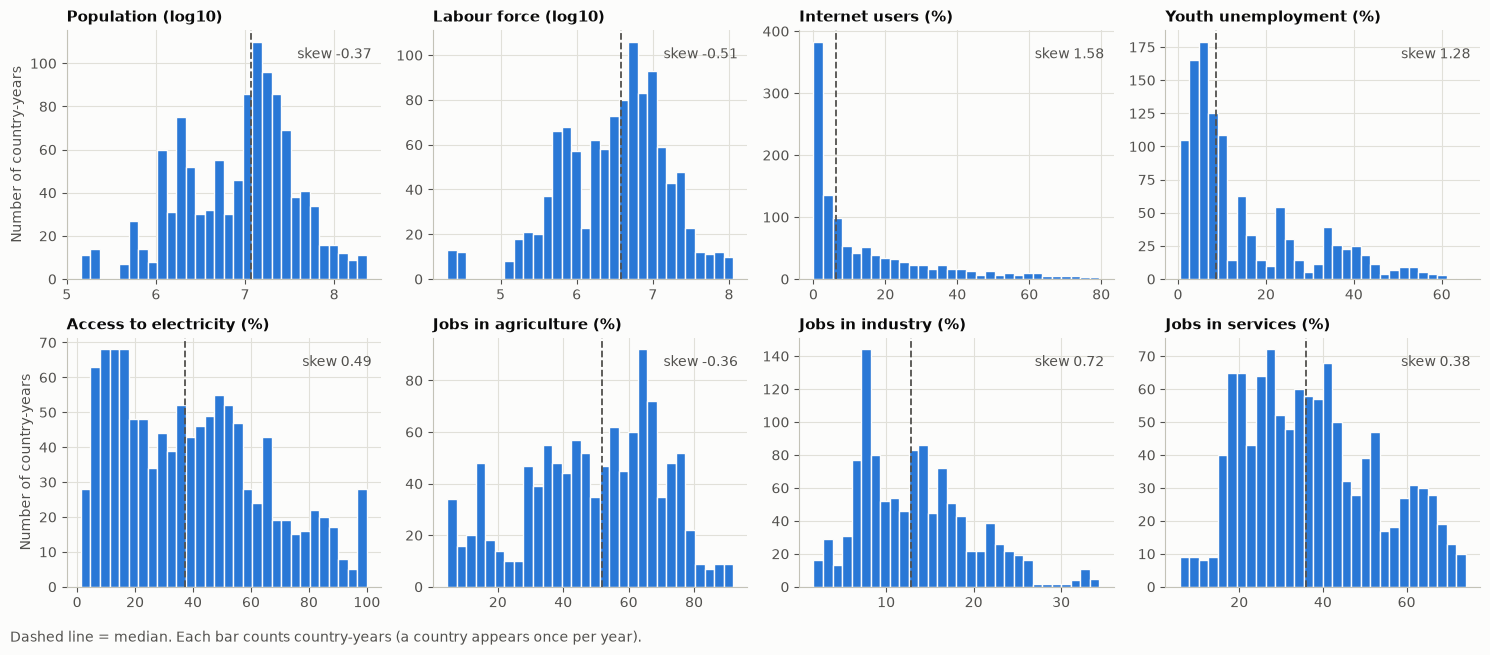

Population     skew: raw 3.55  ->  after log10 -0.37
Labour force   skew: raw 3.92  ->  after log10 -0.51


In [39]:
# Histograms, one panel per variable
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))

for ax, col in zip(axes.flat, num_cols):
    x, title = eda[col], SHORT[col]
    if col in ["population", "labor_force"]:             # strongly skewed -> use a log10 scale
        x, title = np.log10(x), f"{SHORT[col]} (log10)"
    ax.hist(x, bins=30, color=BLUE, edgecolor="#fcfcfb")
    ax.axvline(x.median(), color=INK2, ls="--", lw=1.3)   # dashed line = median
    ax.set_title(title)
    ax.text(0.97, 0.93, f"skew {x.skew():.2f}", transform=ax.transAxes, ha="right", va="top", color=INK2)

for ax in axes[:, 0]:
    ax.set_ylabel("Number of country-years")
    
fig.text(0.01, 0.005, "Dashed line = median. Each bar counts country-years (a country appears once per year).", color=INK2)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

# How much did the log transformation help?
for col in ["population", "labor_force"]:
    print(f"{SHORT[col]:<14} skew: raw {eda[col].skew():.2f}  ->  after log10 {np.log10(eda[col]).skew():.2f}")

In [40]:
len(df_clean[df_clean["internet_usage_percent"] < 3])

406

In [41]:
len(df_clean[(df_clean["youth_unemployment"] >= 3) & (df_clean["youth_unemployment"] <= 10)])

494

In [42]:
df_clean.shape

(1116, 10)

- **Population and labour force:** after the `log10` transformation the skew drops from 3.55 to -0.37 and from 3.92 to -0.51. The shapes are now balanced.
- **Internet use** is piled up near zero: **406 of 1,116** country-years (36%) have under 3% internet use, with a long thin tail up to about 80%.
- **Youth unemployment** has a main peak at **3-10%** (494 rows) and a smaller, separate bump at **30-40%** (106 rows). That second bump hints at **two kinds of country**.
- **Employment in agriculture** has no single peak: some countries have under 20% of jobs in farming, many have 55-70%.
- **Electricity access** covers the whole 0-100% range.

#### How much data each country has, and who has the highest youth unemployment
We dropped incomplete rows during cleaning, some countries kept fewer years than others. 

we rank the countries on our main outcome, **youth unemployment**, in the 2024 snapshot.

Years of data per country (the maximum possible is 25).
Countries with fewer than 20 years: {'Liberia': 18, 'Eritrea': 17, 'Sudan': 9, 'South Sudan': 8}


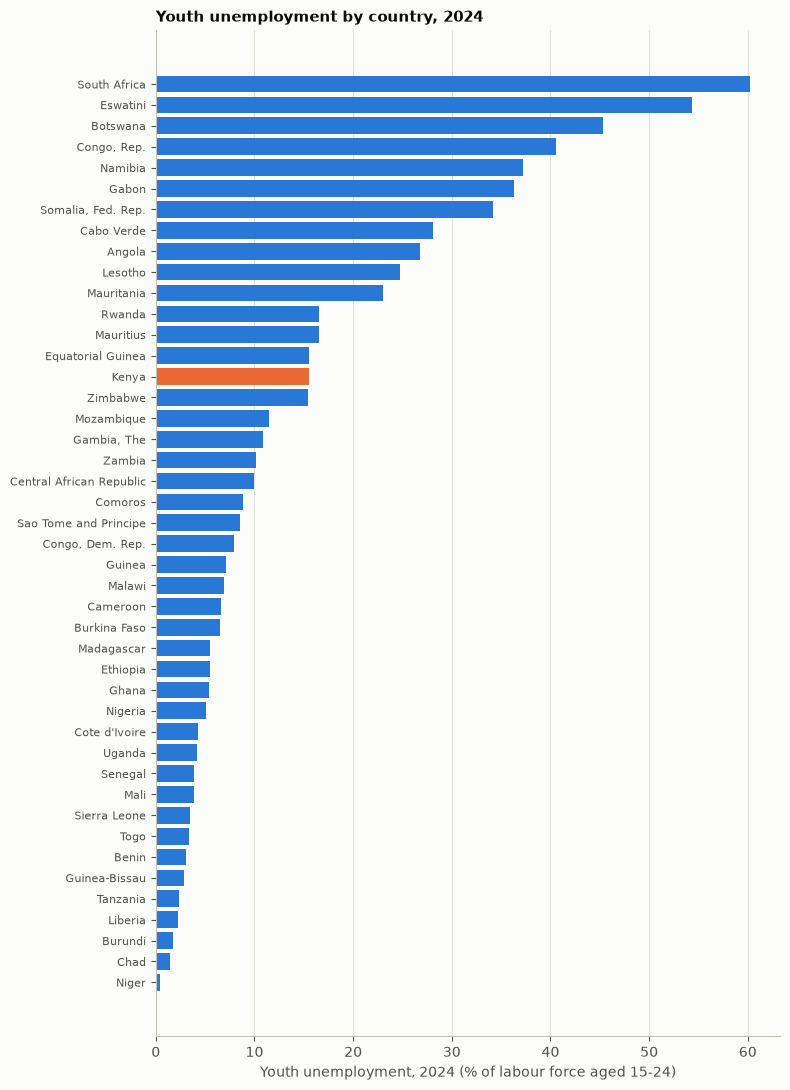

Kenya: 15.5%, rank 15 of 44 (1 = highest). Median of all countries: 8.3%.


In [43]:
# Country coverage and the 2024 ranking of youth unemployment
years_per_country = eda["Country"].value_counts()
print(f"Years of data per country (the maximum possible is {eda['Year'].nunique()}).")
print("Countries with fewer than 20 years:", years_per_country[years_per_country < 20].to_dict())

# Ranking: one bar per country, Kenya in orange
rank = snap["youth_unemployment"].sort_values()

fig, ax = plt.subplots(figsize=(8, 11))
ax.barh(rank.index, rank.values, color=[ORANGE if country == KENYA else BLUE for country in rank.index]) # isolate Kenya in orange
ax.set_xlabel("Youth unemployment, 2024 (% of labour force aged 15-24)")
ax.set_title(f"Youth unemployment by country, {SNAP_YEAR}")
ax.tick_params(axis="y", labelsize=8)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

kenya_rank = int(snap["youth_unemployment"].rank(ascending=False)[KENYA])
print(f"Kenya: {snap.loc[KENYA, 'youth_unemployment']:.1f}%, rank {kenya_rank} of {len(snap)} (1 = highest). "
      f"Median of all countries: {snap['youth_unemployment'].median():.1f}%.")

- **Coverage:** most countries have 20-25 years of data. Four have fewer: **Liberia (18), Eritrea (17), Sudan (9) and South Sudan (8)**, so conclusions about them rest on less evidence.
- **Kenya's youth unemployment in 2024 is 15.5%**, about **double the regional median (8.3%)**. It ranks **15th of 44** (14 countries are higher, 11 are above 20%).
- **The highest:** South Africa (60.2%), Eswatini (54.4%) and Botswana (45.3%). **The lowest:** Niger, Chad and Burundi, all below 2%.
- The lowest rates are in some of the *poorest* countries. This is partly a measurement effect, where most people farm or work informally they count as 'employed', so *recorded* youth unemployment is low even when work is insecure. This matters because the unemployment rate alone does not measure job quality.

#### AI readiness
Is central to the *enhancement* and *emergence* parts of the project: which countries are best prepared for AI, and where is Kenya?

In [44]:
# AI readiness score: distribution and ranking among the 48 countries in the file
ai = ai_readiness_index[["Country", "Ranking", "Total"]].copy()
ai["Ranking"] = ai["Ranking"].astype(int)
ai["rank_in_region"] = ai["Total"].rank(ascending=False).astype(int)      # rank readiness by the region. 1 = most ready of the 48

kenya_score = ai.loc[ai["Country"] == KENYA, "Total"].iloc[0] #isolate Kenya's score

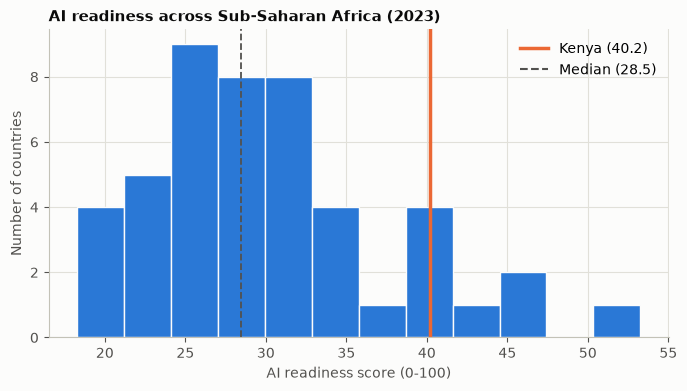

Top 5 and bottom 5 (rank_in_region: 1 = best of the 48; 'Ranking' = the index's own world rank)


,Country,Ranking,Total,rank_in_region
0,Mauritius,61,53.27,1
1,South Africa,77,47.28,2
2,Rwanda,84,45.39,3
3,Senegal,91,42.58,4
4,Benin,97,41.37,5
5,Kenya,101,40.19,6
6,South Sudan,191,18.26,47
7,Eritrea,190,19.62,46
8,Central African Republic,189,19.74,45
9,Burundi,187,20.87,44


In [45]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(ai["Total"], bins=12, color=BLUE, edgecolor="#fcfcfb")
ax.axvline(ai["Total"].median(), color=INK2, ls="--", lw=1.3)
ax.axvline(kenya_score, color=ORANGE, lw=2.5)
ax.set_xlabel("AI readiness score (0-100)"); ax.set_ylabel("Number of countries")
ax.set_title("AI readiness across Sub-Saharan Africa (2023)")
ax.legend(handles=[Line2D([0], [0], color=ORANGE, lw=2.5, label=f"Kenya ({kenya_score:.1f})"),
                   Line2D([0], [0], color=INK2, ls="--", label=f"Median ({ai['Total'].median():.1f})")], frameon=False)
plt.show()

print("Top 5 and bottom 5 (rank_in_region: 1 = best of the 48; 'Ranking' = the index's own world rank)")
pd.concat([ai.sort_values("Total", ascending=False).head(5), ai[ai["Country"] == KENYA], ai.sort_values("Total").head(5)]) \
  .drop_duplicates().reset_index(drop=True)

- Most Sub-Saharan countries score between about **20 and 33**; the median is **28.8**, with a longer tail on the high side.
- **Kenya scores 40.2, 6th of 48** in the region (101st in the index's world ranking). Ahead of it: **Mauritius (53.3), South Africa (47.3), Rwanda (45.4), Senegal (42.6) and Benin (41.4)**.
- The lowest are **South Sudan (18.3), Eritrea (19.6) and the Central African Republic (19.7)**.
- This is a **2023 snapshot** (one number per country), so it lets us compare countries but not study change over time.

#### **2. Bivariate analysis**

#### **Trends over time: Kenya against the region**
We investigate whether Kenya moves with the region or away from it.

For each variable the blue line is the **median country** in each year (a median is not distorted by one extreme country) and the pale band is the **middle 50 %** of countries(interquartile range). Kenya is the orange line

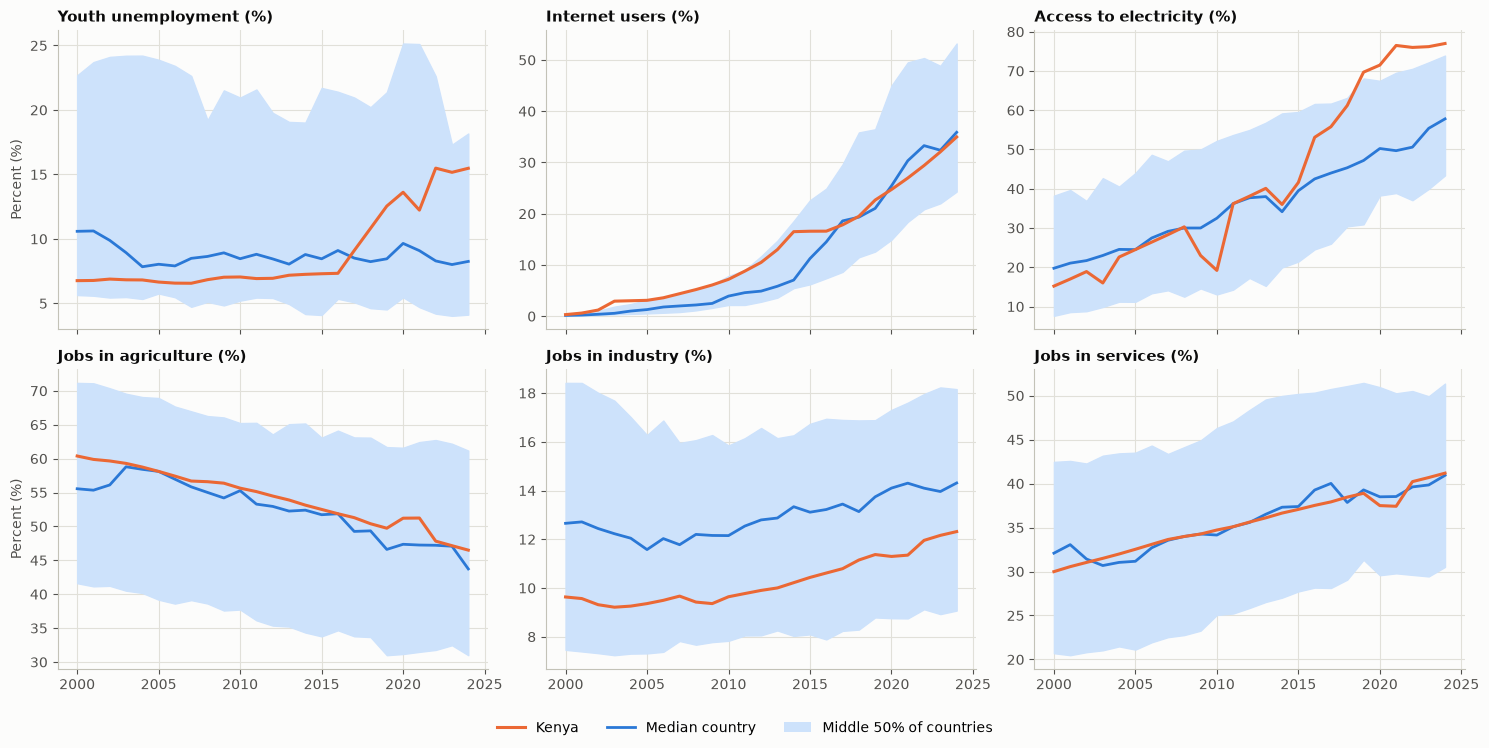

In [46]:
# Each variable against Year: region median + middle 50% band, with Kenya on top
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5), sharex=True)

#calculate the 3 statistical markers (25th, 50th, 75th percentile) for each variable per year
for ax, col in zip(axes.flat, pct_cols):
    q = eda.groupby("Year")[col].quantile([0.25, 0.5, 0.75]).unstack()        # 25th, 50th, 75th percentile per year
    ax.fill_between(q.index, q[0.25], q[0.75], color="#cde2fb")
    ax.plot(q.index, q[0.5], color=BLUE, lw=2)
    kenya = eda[eda["Country"] == KENYA].set_index("Year")[col]
    ax.plot(kenya.index, kenya.values, color=ORANGE, lw=2.2)
    ax.set_title(SHORT[col])

for ax in axes[:, 0]:
    ax.set_ylabel("Percent (%)")
    
fig.legend(handles=[Line2D([0], [0], color=ORANGE, lw=2.2, label="Kenya"),
                    Line2D([0], [0], color=BLUE, lw=2, label="Median country"),
                    Patch(facecolor="#cde2fb", label="Middle 50% of countries")],
           loc="lower center", ncol=3, frameon=False)
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

**Insights**
- **Youth unemployment:** the median country barely moves (**10.6% in 2000 to 8.3% in 2024**). Kenya is different: it stayed near **7%** until 2016, then rose to **9.1% (2017), 12.5% (2019) and 15.5% (2022-2024)**, going above the median country for the first time in **2017**.
- **Internet:** Kenya follows the regional median closely (35% vs 36% in 2024). It is not ahead on adoption.
- **Electricity:** in line with the median until about 2010 (with an odd dip to about 19% that year), then clearly ahead: **77% vs 58%** in 2024.
- **Agriculture and services:** Kenya tracks the regional trend almost exactly. Farm jobs fell from **60% to 46.5%** and services rose from **30% to 41%**. Kenya's **industry** share is below the median throughout (12.3% vs 14.3% in 2024).
- **Kenya's structure and connectivity moved like the rest of the region, but its youth unemployment did not.** This is the paradox from the business understanding, now visible in the data.
- **Cautions:** the median line wobbles a little because the set of countries changes slightly from year to year. Also, youth unemployment is an ILO *modelled estimate*, so the abrupt step after 2016 should be checked against Kenya's own labour-force surveys before we rely on it.

#### **Three ways to measure the link with Unemployment**

- **All rows:** every country-year together.
- **Between countries:** one point per country (its 2000-2024 average). *Do countries that are more connected tend to have higher youth unemployment?*
- **Within countries:** each country compared only with **itself** over time. *When a country becomes more connected, does its own youth unemployment change?*

In [47]:
# Spearman correlation with youth unemployment: all rows vs between countries vs within countries
target = "youth_unemployment"
factors = ["agriculture_employment", "industry_employment", "services_employment",
          "internet_usage_percent", "electricity_access", "log_population", "log_labor_force"]
cols = factors + [target]

country_means = eda.groupby("Country")[cols].mean()                              # 1 row per country -> BETWEEN countries
deviations_from_mean = eda[cols] - eda.groupby("Country")[cols].transform("mean")           # each country minus its own average -> WITHIN

corr_tbl = pd.DataFrame({
    "all rows": eda[factors].corrwith(eda[target], method="spearman"),
    "between countries": country_means[factors].corrwith(country_means[target], method="spearman"),
    "within countries (over time)": deviations_from_mean[factors].corrwith(deviations_from_mean[target], method="spearman"),
})
corr_tbl.index = [SHORT[c].replace(" (%)", "") for c in factors] # format index labels for display

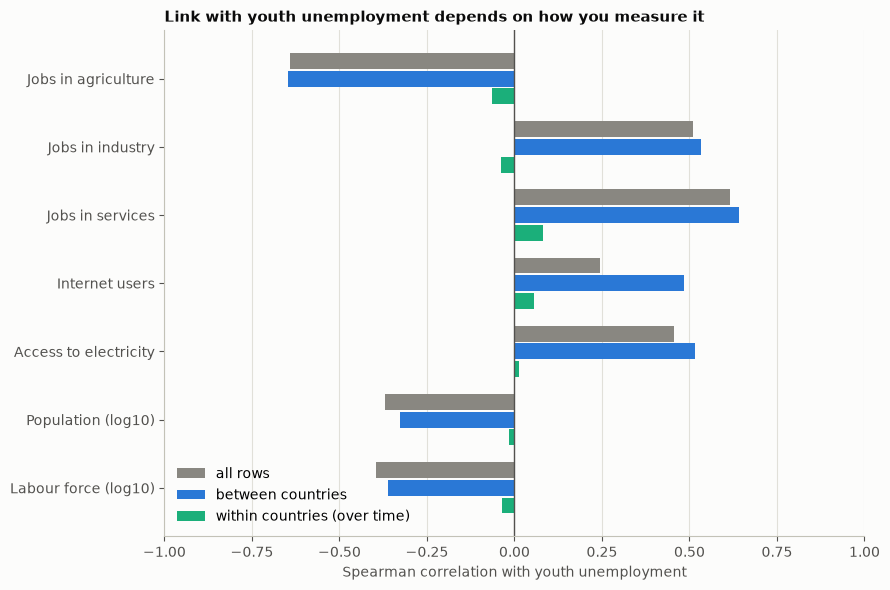

,all rows,between countries,within countries (over time)
Jobs in agriculture,-0.64,-0.65,-0.06
Jobs in industry,0.51,0.53,-0.04
Jobs in services,0.62,0.64,0.08
Internet users,0.24,0.48,0.06
Access to electricity,0.45,0.52,0.01
Population (log10),-0.37,-0.33,-0.01
Labour force (log10),-0.40,-0.36,-0.03


In [48]:
# Grouped horizontal bars: three bars per variable
fig, ax = plt.subplots(figsize=(9, 6))

y = np.arange(len(corr_tbl)); h = 0.26

for i, (name, colr) in enumerate(zip(corr_tbl.columns, [GREY, BLUE, AQUA])):
    ax.barh(y + (i - 1) * h, corr_tbl[name], height=h * 0.9, color=colr, label=name)
ax.axvline(0, color=INK2, lw=1)
ax.set_yticks(y); ax.set_yticklabels(corr_tbl.index); ax.invert_yaxis()
ax.set_xlabel("Spearman correlation with youth unemployment"); ax.set_xlim(-1, 1)
ax.set_title("Link with youth unemployment depends on how you measure it")
ax.legend(frameon=False, loc="lower left")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

corr_tbl.round(2)       # the same numbers as a table


- **Between countries** (blue) the links are strong. Countries with more **services jobs (0.64)**, **industry jobs (0.53)**, **electricity (0.52)** and **internet use (0.48)** tend to have *higher* youth unemployment; countries with more **agriculture jobs (-0.65)** tend to have *lower*.
- **Within countries over time** (green): every correlation is between **-0.06 and +0.08**. When a country becomes more connected or shifts towards services, its own youth unemployment does not systematically follow.
- The **all rows** bars (grey) are a blend of the two. For internet use the blend (0.24) understates the between-country link (0.48), because internet use rose everywhere over time while youth unemployment mostly did not.

#### **comparing countries in 2024**
 We use the **2024 snapshot** (one point per country) so that no country is counted twice. The grey line is a straight-line fit and ρ (rho) is the Spearman correlation. Kenya is orange; the three countries with the highest youth unemployment are named.

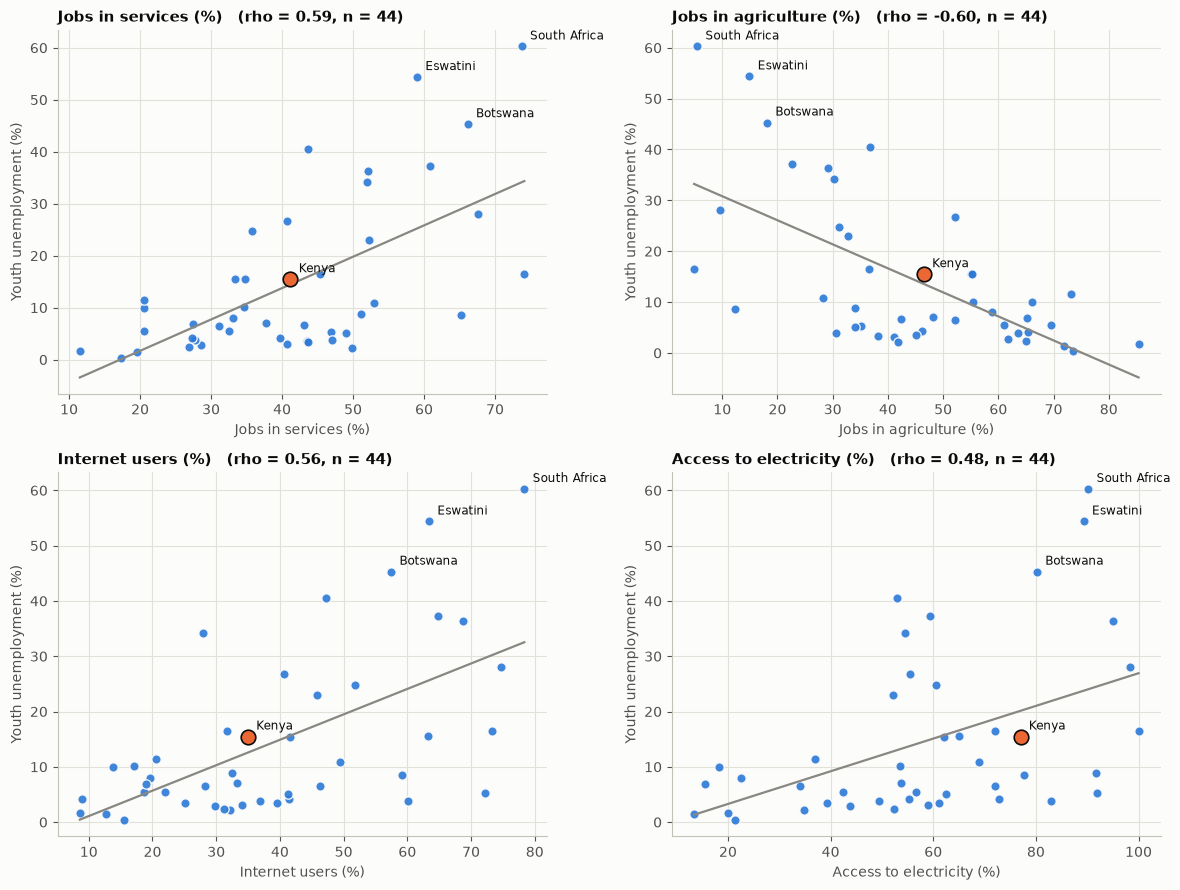

In [49]:
# Youth unemployment vs four drivers, one point per country (2024)
pairs = ["services_employment", "agriculture_employment", "internet_usage_percent", "electricity_access"]
named = [KENYA] + snap["youth_unemployment"].nlargest(3).index.tolist()          # countries to label

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, xcol in zip(axes.flat, pairs):
    d = snap[[xcol, "youth_unemployment"]].dropna()
    ax.scatter(d[xcol], d["youth_unemployment"], s=45, color=BLUE, edgecolor="#fcfcfb", linewidth=1, alpha=0.9)
    slope, intercept = np.polyfit(d[xcol], d["youth_unemployment"], 1)           # straight-line fit
    xs = np.array([d[xcol].min(), d[xcol].max()])
    ax.plot(xs, slope * xs + intercept, color=GREY, lw=1.6)
    ax.scatter(d.loc[KENYA, xcol], d.loc[KENYA, "youth_unemployment"], s=110, color=ORANGE, edgecolor=INK, linewidth=1.2, zorder=3)

    for c in named:
        ax.annotate(c, (d.loc[c, xcol], d.loc[c, "youth_unemployment"]), xytext=(6, 5), textcoords="offset points", fontsize=8.5, color=INK)
    rho = d[xcol].corr(d["youth_unemployment"], method="spearman")
    ax.set_title(f"{SHORT[xcol]}   (rho = {rho:.2f}, n = {len(d)})")
    ax.set_xlabel(SHORT[xcol]); ax.set_ylabel("Youth unemployment (%)")

plt.tight_layout()
plt.show()

- Across countries in 2024 the pattern is consistent: youth unemployment is **higher where services jobs are higher (rho 0.59), where agriculture jobs are lower (-0.60), and where internet use (0.56) and electricity access (0.48) are higher** (n = 44).
- Many countries sit at 0-10% unemployment across the *whole* range of each x variable, while a small group (South Africa, Eswatini, Botswana at 45-60%) pulls the line up. This matches the two-bump shape we saw in the histogram.
- **Kenya sits close to the line in all four panels.** Its actual 15.5% is within about 1-5 points of what the line predicts (services 14.5, agriculture 13.6, internet 12.6, electricity 20.1). So in 2024 Kenya's youth unemployment looks about normal for a country with its job structure and connectivity; what is unusual is how quickly it got there.

#### **Change over time: did the countries that changed most see unemployment move most?**
**how much each country changed between 2000 and 2024**. This is the closest the data gets to asking *"when a country digitises or shifts to services, what happens to youth unemployment?"* (only countries with data in both years are used).

In [50]:
# Change 2000 -> 2024 (in percentage points) for each country
a = eda[eda["Year"] == 2000].set_index("Country")
b = eda[eda["Year"] == 2024].set_index("Country")
both = a.index.intersection(b.index)                          # countries with data in BOTH years
difference = (b.loc[both, pct_cols] - a.loc[both, pct_cols])         # positive = the share went up
print(f"{len(both)} countries have data in both 2000 and 2024")

42 countries have data in both 2000 and 2024


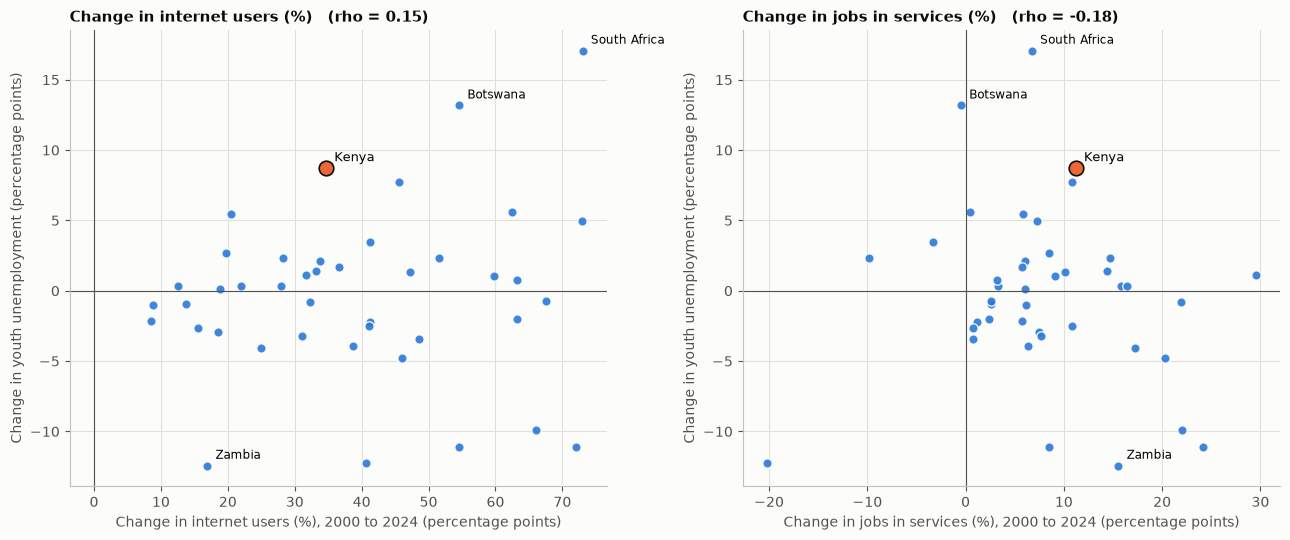

Kenya's changes 2000 -> 2024 (percentage points):


Youth unemployment (%)        8.70
Internet users (%)           34.70
Access to electricity (%)    61.80
Jobs in agriculture (%)     -13.90
Jobs in industry (%)          2.70
Jobs in services (%)         11.20
Name: Kenya, dtype: float64

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

for ax, xcol in zip(axes, ["internet_usage_percent", "services_employment"]):
    ax.axhline(0, color=INK2, lw=0.8); ax.axvline(0, color=INK2, lw=0.8)
    ax.scatter(difference[xcol], difference["youth_unemployment"], s=45, color=BLUE, edgecolor="#fcfcfb", linewidth=1, alpha=0.9)
    ax.scatter(difference.loc[KENYA, xcol], difference.loc[KENYA, "youth_unemployment"], s=110, color=ORANGE, edgecolor=INK, linewidth=1.2, zorder=3)
    ax.annotate(KENYA, (difference.loc[KENYA, xcol], difference.loc[KENYA, "youth_unemployment"]), xytext=(6, 5), textcoords="offset points", fontsize=9)

    for c in difference["youth_unemployment"].nlargest(2).index.tolist() + difference["youth_unemployment"].nsmallest(1).index.tolist():
        if c != KENYA:
            ax.annotate(c, (difference.loc[c, xcol], difference.loc[c, "youth_unemployment"]), xytext=(6, 5), textcoords="offset points", fontsize=8.5)

    rho = difference[xcol].corr(difference["youth_unemployment"], method="spearman")
    ax.set_title(f"Change in {SHORT[xcol].lower()}   (rho = {rho:.2f})")
    ax.set_xlabel(f"Change in {SHORT[xcol].lower()}, 2000 to 2024 (percentage points)")
    ax.set_ylabel("Change in youth unemployment (percentage points)")
plt.tight_layout()
plt.show()

print("Kenya's changes 2000 -> 2024 (percentage points):")
difference.loc[KENYA, pct_cols].round(1).rename(index=SHORT)

**Insights**
- Between 2000 and 2024 youth unemployment **rose in 22 countries and fell in 20** (42 countries have data in both years).
- **Kenya rose by 8.7 points, the 3rd largest rise**, after **South Africa (+17.1)** and **Botswana (+13.2)**. The biggest falls were **Zambia (-12.4), Angola (-12.3) and Sao Tome and Principe (-11.1)**.
- **There is no clear pattern** with the change in internet use (rho 0.15) or in services jobs (rho -0.18). Of the **12 countries that gained 50 or more points of internet use**, 7 saw youth unemployment rise and 5 saw it fall, within a range of -11.1 to +17.1 points.
- Kenya's own changes: internet **+34.7**, electricity **+61.8**, services **+11.2**, agriculture **-13.9**, industry **+2.7** points. Other countries changed as much and saw unemployment fall.
- This agrees with the within-country result in 2.2: becoming more connected or more services-based does not, on its own, tell us which countries will see youth unemployment rise.

### **AI readiness against connectivity and unemployment**
AI readiness is one score per country, so it is compared with the **2024 snapshot** values. The first panel asks whether readiness simply follows how many people are online; the second asks whether it goes with youth unemployment.

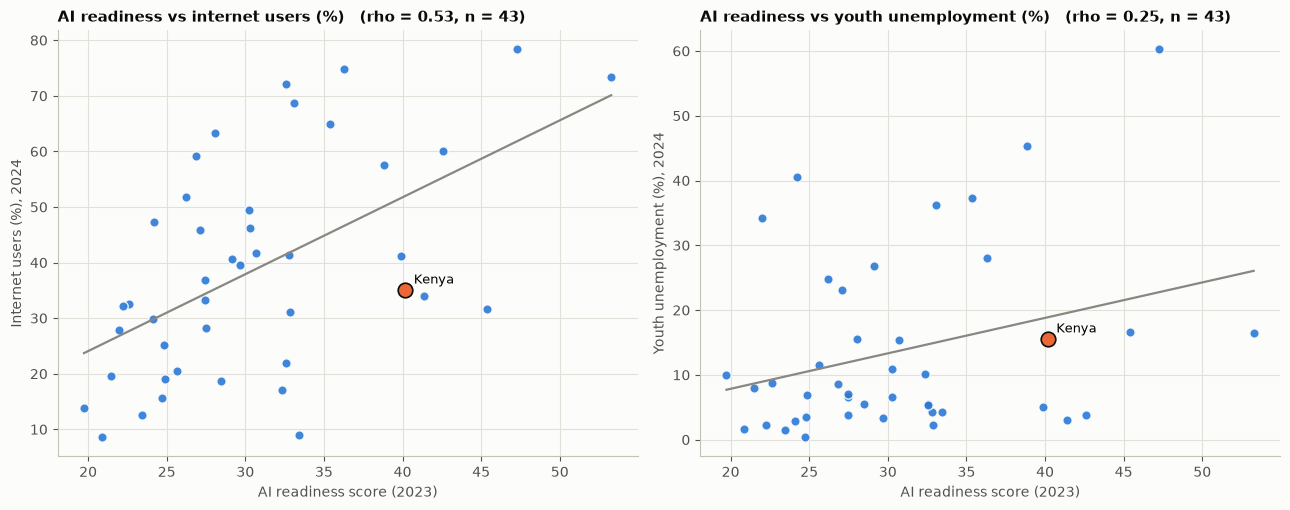

In [52]:
# AI readiness vs internet use and youth unemployment (one point per country)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

for ax, ycol in zip(axes, ["internet_usage_percent", "youth_unemployment"]):
    d = snap[["ai_total", ycol]].dropna()
    ax.scatter(d["ai_total"], d[ycol], s=45, color=BLUE, edgecolor="#fcfcfb", linewidth=1, alpha=0.9)
    slope, intercept = np.polyfit(d["ai_total"], d[ycol], 1)
    xs = np.array([d["ai_total"].min(), d["ai_total"].max()])
    ax.plot(xs, slope * xs + intercept, color=GREY, lw=1.6)
    ax.scatter(d.loc[KENYA, "ai_total"], d.loc[KENYA, ycol], s=110, color=ORANGE, edgecolor=INK, linewidth=1.2, zorder=3)
    ax.annotate(KENYA, (d.loc[KENYA, "ai_total"], d.loc[KENYA, ycol]), xytext=(6, 5), textcoords="offset points", fontsize=9)
    rho = d["ai_total"].corr(d[ycol], method="spearman")
    ax.set_title(f"AI readiness vs {SHORT[ycol].lower()}   (rho = {rho:.2f}, n = {len(d)})")
    ax.set_xlabel("AI readiness score (2023)"); ax.set_ylabel(f"{SHORT[ycol]}, {SNAP_YEAR}")
plt.tight_layout()
plt.show()

**Insights**
- **AI readiness goes with connectivity** (rho 0.53, n = 43), but loosely: countries with readiness scores of 25-35 have internet use anywhere from about **9% to 75%**. High readiness on paper does not guarantee that people are online.
- **Kenya is well below the line in the left panel.** With a readiness of 40.2 the line predicts internet use of about **52%**, but Kenya's is **35%**, roughly **17 points lower**. Readiness (policy, technology sector, infrastructure) is ahead of everyday adoption.
- **AI readiness has only a weak link to youth unemployment** (rho 0.25), so it does not tell us on its own which countries have a jobs problem. Its value for this project is for the *enhancement* and *emergence* questions (who could benefit from AI), not for explaining unemployment.


#### **3. Multivariate analysis**

Correlation Heat Map



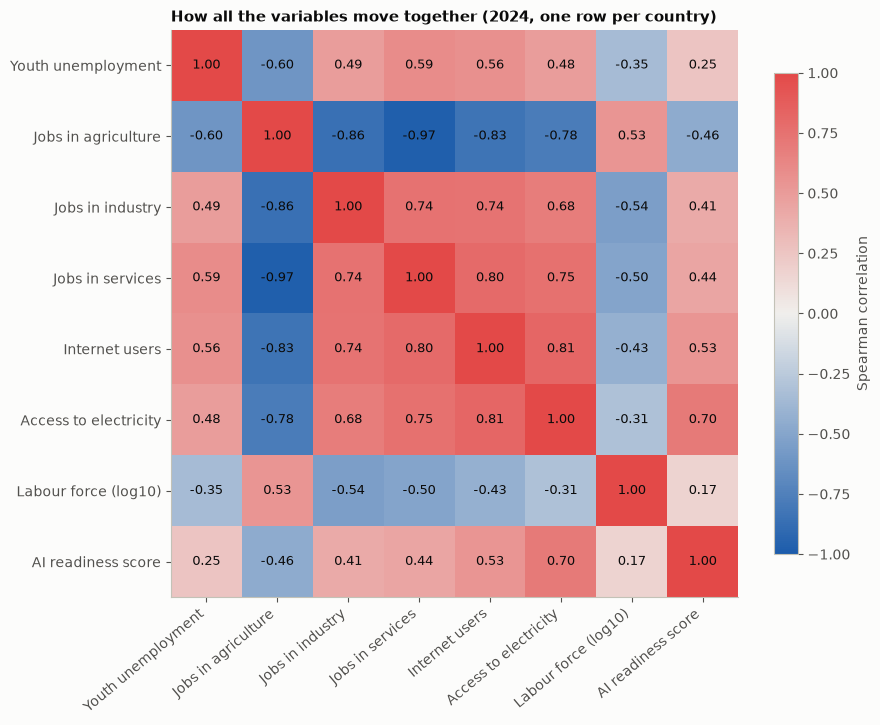

In [53]:
# Spearman correlation heat map (2024 snapshot)
heat_cols = ["youth_unemployment", "agriculture_employment", "industry_employment", "services_employment",
             "internet_usage_percent", "electricity_access", "log_labor_force", "ai_total"]

cm = snap[heat_cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(cm, cmap=DIV, vmin=-1, vmax=1)
labels = [SHORT[c].replace(" (%)", "") for c in heat_cols]

ax.set_xticks(range(len(heat_cols))); ax.set_xticklabels(labels, rotation=40, ha="right")
ax.set_yticks(range(len(heat_cols))); ax.set_yticklabels(labels)
ax.grid(False)

# get the correlation values and add them as text annotations on the heatmap
for i in range(len(heat_cols)):
    for j in range(len(heat_cols)):
        v = cm.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9, color=INK)
        
fig.colorbar(im, ax=ax, shrink=0.8, label="Spearman correlation")
ax.set_title(f"How all the variables move together ({SNAP_YEAR}, one row per country)")
plt.tight_layout()
plt.show()

**Insights**
- **Youth unemployment** goes with agriculture jobs (**-0.60**), services (**0.59**), internet (**0.56**), industry (**0.49**), electricity (**0.48**), labour force (**-0.35**) and AI readiness (**0.25**).
- **Services and agriculture are almost mirror images (-0.97)**, because the three job shares add up to 100%. They carry nearly the same information.
- **Many predictors move together.** Internet, electricity, services and industry are all correlated with each other at **0.68-0.81**.
- **AI readiness** goes most with **electricity (0.70)** and internet (0.53), and against agriculture (-0.46): readiness is higher where infrastructure is better.
- **Labour force size** goes with agriculture (0.53) and against industry, services, internet and electricity (-0.31 to -0.54): large labour forces are more farm-based and less connected.

#### **Grouping countries by how farm-based they are**
We split them into **three equal-sized groups by agriculture share** (low, medium, high) and compare the groups on *all* the other variables at once. 

This is a simple, readable "profile" of each type of country and shows where Kenya sits.

In [54]:
# Profile table + box plots for three groups of countries (by agriculture share, 2024)
snap["agri_group"] = pd.qcut(snap["agriculture_employment"], 3,
                             labels=["Low agriculture", "Medium agriculture", "High agriculture"])

profile = snap.groupby("agri_group", observed=True).agg(
    countries=("youth_unemployment", "size"),
    agriculture=("agriculture_employment", "mean"), services=("services_employment", "mean"),
    internet=("internet_usage_percent", "mean"), electricity=("electricity_access", "mean"),
    ai_readiness=("ai_total", "mean"), youth_unemployment=("youth_unemployment", "mean"),
    median_labour_force_millions=("labor_force", lambda s: s.median() / 1e6))

display(profile)
print(f"Kenya is in the '{snap.loc[KENYA, 'agri_group']}' group.")

for g_name, members in snap.groupby("agri_group", observed=True):
    print(f"\n{g_name}: " + ", ".join(sorted(members.index))) # print out countries in each group

,countries,agriculture,services,internet,electricity,ai_readiness,youth_unemployment,median_labour_force_millions
agri_group,,,,,,,,
Low agriculture,15,22.55,57.28,56.59,77.57,34.40,26.47,0.88
Medium agriculture,14,44.12,41.57,40.73,60.10,31.12,11.21,6.06
High agriculture,15,66.05,25.46,21.05,37.57,26.85,5.97,8.86


Kenya is in the 'Medium agriculture' group.

Low agriculture: Botswana, Cabo Verde, Comoros, Eswatini, Gabon, Gambia, The, Lesotho, Mauritania, Mauritius, Namibia, Nigeria, Sao Tome and Principe, Senegal, Somalia, Fed. Rep., South Africa

Medium agriculture: Angola, Benin, Burkina Faso, Cameroon, Congo, Rep., Cote d'Ivoire, Equatorial Guinea, Ghana, Guinea, Kenya, Liberia, Rwanda, Sierra Leone, Togo

High agriculture: Burundi, Central African Republic, Chad, Congo, Dem. Rep., Ethiopia, Guinea-Bissau, Madagascar, Malawi, Mali, Mozambique, Niger, Tanzania, Uganda, Zambia, Zimbabwe


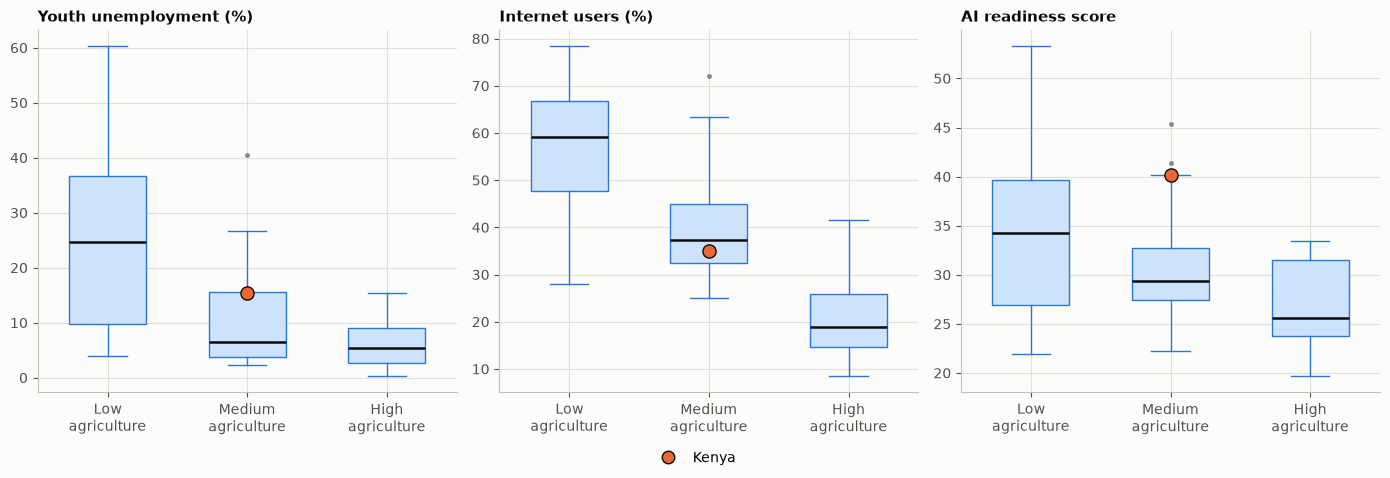

In [55]:
# Box plots of three outcomes by group, Kenya as an orange dot
groups = list(profile.index)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.8))

for ax, col in zip(axes, ["youth_unemployment", "internet_usage_percent", "ai_total"]):
    ax.boxplot([snap.loc[snap["agri_group"] == g_name, col].dropna() for g_name in groups], widths=0.55, patch_artist=True,
               boxprops=dict(facecolor="#cde2fb", edgecolor=BLUE), medianprops=dict(color=INK, lw=1.8),
               whiskerprops=dict(color=BLUE), capprops=dict(color=BLUE),
               flierprops=dict(marker="o", markersize=3.5, markerfacecolor=GREY, markeredgecolor="none"))
    ax.scatter(groups.index(snap.loc[KENYA, "agri_group"]) + 1, snap.loc[KENYA, col], s=90, color=ORANGE, edgecolor=INK, zorder=3)
    ax.set_xticks([1, 2, 3]); ax.set_xticklabels([g_name.replace(" ", "\n") for g_name in groups])
    ax.set_title(SHORT[col])
    
fig.legend(handles=[Line2D([0], [0], marker="o", color="none", markerfacecolor=ORANGE, markeredgecolor=INK, markersize=9, label="Kenya")],
           loc="lower center", frameon=False)
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

**Insights**
- As agriculture falls, **everything else rises.** Average youth unemployment goes **5.97% to 11.2% to 26.5%** from the high- to the medium- to the low-agriculture group; internet use **21.05% to 40.73% to 56.59%**; electricity **37% to 60% to 77%**; AI readiness about **26.85 to 31.12 to 34.40**.
- The **low-agriculture group is by far the most mixed** (youth unemployment from about 4% to 60%), so being less farm-based does not point to one particular unemployment level.
- **Kenya is in the medium group.** Within it, Kenya is **at the top end for youth unemployment** (15.5% vs a group average of 11.2%), **below average for internet use** (35% vs 41%) and **above average for AI readiness** (40.2 vs 31.1).
- The low-agriculture group is mostly made up of smaller economies (median labour force **0.9 million**, against 6.1 and 8.9 million in the other two groups).


#### Analysis Summary
1. **Youth unemployment has two faces.** Most country-years sit at 3-10%, and a second group sits at 30-40% (Eswatini, South Africa, Botswana and similar). Kenya (15.5%, 15th of 44) is above the regional median (8.3%) but far from the extremes.
2. **'What kind of country' explains a lot; 'how a country changes' explains almost nothing.** Between countries, recorded youth unemployment is higher where there are fewer farm jobs and more services, internet and electricity (correlations of about 0.5-0.65). Within a country over time those links vanish (at most 0.08), and the countries that changed most in internet use or services jobs did not share a common unemployment trend.
3. **Kenya's structure moved like the region's, but its youth unemployment did not.** It stayed near 7% until 2016, then rose to 15.5% (the 3rd largest rise of 42 countries). In 2024 it is close to what its job structure and connectivity predict. 
4. **Kenya is ready for AI on paper, less so in practice.** It is 6th of 48 on AI readiness, but its internet use (35%) is about 17 points below what its readiness would suggest.
5. **Link to the three axes (with limits):** the data has job *sectors*, not occupations, so it cannot rank which jobs AI would replace. It does show *where* the conditions for **enhancement** exist (connected, services-led countries; Kenya is in the middle) and that for **emergence** Kenya's foundations score well.

In [56]:
# df_clean.to_csv("sub_saharan_data.csv", index=False)
# ai_readiness_index.to_csv("sub_saharan_ai_readiness.csv", index=False)

In [ ]:
snap.head()

,Country,Year,population,labor_force,internet_usage_percent,youth_unemployment,electricity_access,agriculture_employment,industry_employment,services_employment
0,Angola,2000,"16,194,869.00","6,813,281.00",0.11,39.01,24.20,30.91,8.21,60.88
1,Angola,2001,"16,747,208.00","7,055,911.00",0.14,38.99,20.00,30.72,8.34,60.94
2,Angola,2002,"17,327,699.00","7,311,174.00",0.27,38.43,26.30,30.55,8.54,60.90
3,Angola,2003,"17,943,712.00","7,582,160.00",0.37,38.40,27.40,30.67,8.62,60.71
4,Angola,2004,"18,600,423.00","7,870,095.00",0.46,38.09,28.40,30.89,8.68,60.43


# **Modelling**

In [ ]:
# creating a new df for modelling and attaching the AI readiness score to it.
model_df = eda.copy()
model_df["code"] = model_df["Country"].map(snap["code"]) #mapping country names to country codes
model_df["ai_total"] = model_df["code"].map(ai_readiness_index.set_index("CountryCode")["Total"]) #including the ai readiness score in the modelling df


print("Rows with an AI score:", int(model_df["ai_total"].notna().sum()), "of", len(model_df))

Rows with an AI score: 1057 of 1116


In [74]:
model_df.shape

(1116, 14)

In [76]:
model_df.isna().sum()

Country                    0
Year                       0
population                 0
labor_force                0
internet_usage_percent     0
youth_unemployment         0
electricity_access         0
agriculture_employment     0
industry_employment        0
services_employment        0
log_population             0
log_labor_force            0
code                      34
ai_total                  59
dtype: int64

In [60]:
TARGET =  "youth_unemployment"
FEATURES = ["agriculture_employment", "industry_employment", "services_employment",
            "internet_usage_percent", "electricity_access", "log_population", "log_labor_force", "ai_total"]

X = model_df[FEATURES].reset_index(drop=True) # inputs
y = model_df[TARGET].reset_index(drop=True) # outputs
groups = model_df["Country"].to_numpy() # which country each row belongs to.

print(f"Rows: {len(X)} | countries: {len(set(groups))} | features: {len(FEATURES)}")
print("Missing values per feature:", X.isna().sum()[X.isna().sum() > 0].to_dict())
print("Countries with no AI readiness score:", sorted(model_df.loc[model_df["ai_total"].isna(), "Country"].unique()))
print(f"Target: mean {y.mean():.1f}%, median {np.median(y):.1f}%, std {y.std():.1f} points")


Rows: 1116 | countries: 47 | features: 8
Missing values per feature: {'ai_total': 59}
Countries with no AI readiness score: ['Eritrea', 'Eswatini', 'South Sudan', 'Sudan']
Target: mean 14.9%, median 8.5%, std 14.0 points


- The table has **1,116 rows** (47 countries) and 8 features. The only missing values are the AI readiness score for **Eswatini, Eritrea, South Sudan, and Sudan**, which each model fills with the training median.
- Youth unemployment averages **14.9%**, but the typical (median) value is **8.5%**, with a standard deviation of **14.0 points**. A model that always predicts the average will be off by roughly 14 points.


In [61]:
# --- Country-based folds: whole COUNTRIES are assigned to a fold, never single rows ---
def make_folds(groups, n_splits, seed):
    """Return a list of (train_rows, test_rows). Each country sits entirely in train or entirely in test."""
    rng = np.random.default_rng(seed)
    countries = np.array(sorted(set(groups)))
    rng.shuffle(countries)                                         # a different shuffle for every seed
    fold_of = {c: i % n_splits for i, c in enumerate(countries)}   # deal countries out like cards
    fold_id = np.array([fold_of[g] for g in groups])
    return [(np.where(fold_id != k)[0], np.where(fold_id == k)[0]) for k in range(n_splits)]

# Check the folds: sizes, and that no country appears on both sides
for k, (tr, te) in enumerate(make_folds(groups, 5, seed=0)):
    overlap = set(groups[tr]) & set(groups[te])
    print(f"fold {k + 1}: train {len(set(groups[tr]))} countries / {len(tr)} rows | test {len(set(groups[te]))} countries / {len(te)} rows | shared countries: {len(overlap)}")

fold 1: train 37 countries / 868 rows | test 10 countries / 248 rows | shared countries: 0
fold 2: train 37 countries / 874 rows | test 10 countries / 242 rows | shared countries: 0
fold 3: train 38 countries / 909 rows | test 9 countries / 207 rows | shared countries: 0
fold 4: train 38 countries / 917 rows | test 9 countries / 199 rows | shared countries: 0
fold 5: train 38 countries / 896 rows | test 9 countries / 220 rows | shared countries: 0


- Each test fold holds **9-10 whole countries** (about 200-250 rows), and the check shows **0 shared countries** between training and testing, so no model can recognise a country it was trained on.

#### **Unsupervised Learning: Using K-means to find types of country**

Grouping the countries using the 2024 snapshot (one row per country) and standardise the features first so that none dominates.

We determine the best value of K (number of groups) by calculating:
- Silhouette score - How well each country fits its own group compared with the next closest group.
- Inertia/Elbow method - Total spread inside the groups. We look where the drop slows down.

In [62]:
# Choose k for K-means (2024 snapshot, one row per country)
prep = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
Xs = prep.fit_transform(snap[FEATURES])           # standardised features: mean 0, std 1

ks = range(2, 8)
sil, inertia = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(Xs)
    sil.append(silhouette_score(Xs, km.labels_))
    inertia.append(km.inertia_)
print(pd.DataFrame({"k": list(ks), "silhouette": sil, "inertia": inertia}).set_index("k").round(2))


   silhouette  inertia
k                     
2        0.35   196.57
3        0.29   151.20
4        0.26   121.61
5        0.24   107.06
6        0.24    92.30
7        0.24    83.81


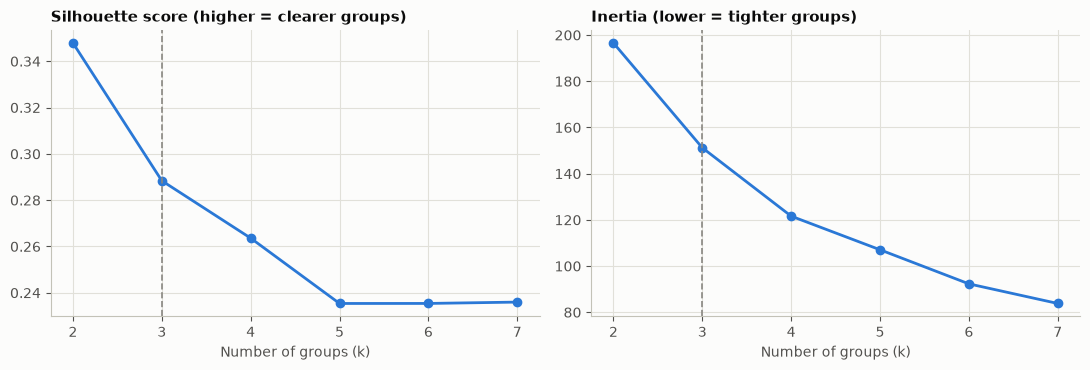

In [63]:
K = 3
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, vals, title in zip(axes, [sil, inertia], ["Silhouette score (higher = clearer groups)", "Inertia (lower = tighter groups)"]):
    ax.plot(list(ks), vals, marker="o", color=BLUE, lw=2)
    ax.axvline(K, color=GREY, ls="--", lw=1.2)
    ax.set_title(title); ax.set_xlabel("Number of groups (k)")
plt.tight_layout()
plt.show()

- The silhouette is highest at **k = 2 (0.35)**, but that split only separates farm-based countries from the rest. It then drops to **0.29 at k = 3** and stays between **0.24 and 0.26** for k = 4 to 7.
- The inertia falls smoothly, with no sharp elbow, so it does not point to one k either.
- We choose **k = 3**

In [64]:
# Fit K-means with k = 3 and describe the three types of country
km = KMeans(n_clusters=K, n_init=20, random_state=42).fit(Xs)
snap["cluster"] = km.labels_

In [65]:
# Name the clusters by how farm-based they are (highest agriculture share first)
order = snap.groupby("cluster")["agriculture_employment"].mean().sort_values(ascending=False).index
names = ["Farm-based and offline", "In transition", "Services-led and connected"]
cluster_name = {c: n for c, n in zip(order, names)}
snap["cluster_name"] = snap["cluster"].map(cluster_name)

# Profile table: average of every feature per type. Youth unemployment was NOT used to build the groups.
profile_km = snap.groupby("cluster_name").agg(
    countries=("youth_unemployment", "size"),
    agriculture=("agriculture_employment", "mean"), industry=("industry_employment", "mean"),
    internet=("internet_usage_percent", "mean"), electricity=("electricity_access", "mean"),
    ai_readiness=("ai_total", "mean"), median_labour_force_millions=("labor_force", lambda s: s.median() / 1e6),
    youth_unemployment_NOT_USED=("youth_unemployment", "mean")).loc[names]
display(profile_km)
print(f"Kenya is in: {snap.loc[KENYA, 'cluster_name']}")
for n in names:
    print(f"\n{n}: " + ", ".join(sorted(snap.index[snap['cluster_name'] == n])))

,countries,agriculture,industry,internet,electricity,ai_readiness,median_labour_force_millions,youth_unemployment_NOT_USED
cluster_name,,,,,,,,
Farm-based and offline,20,61.52,9.24,23.77,39.05,26.69,8.47,6.78
In transition,12,35.28,17.54,46.24,70.74,35.68,8.81,16.55
Services-led and connected,12,24.41,19.59,58.71,78.22,32.54,0.75,25.78


Kenya is in: In transition

Farm-based and offline: Angola, Burkina Faso, Burundi, Central African Republic, Chad, Congo, Dem. Rep., Ethiopia, Guinea, Guinea-Bissau, Liberia, Madagascar, Malawi, Mali, Mozambique, Niger, Sierra Leone, Tanzania, Uganda, Zambia, Zimbabwe

In transition: Benin, Cameroon, Congo, Rep., Cote d'Ivoire, Ghana, Kenya, Nigeria, Rwanda, Senegal, Somalia, Fed. Rep., South Africa, Togo

Services-led and connected: Botswana, Cabo Verde, Comoros, Equatorial Guinea, Eswatini, Gabon, Gambia, The, Lesotho, Mauritania, Mauritius, Namibia, Sao Tome and Principe


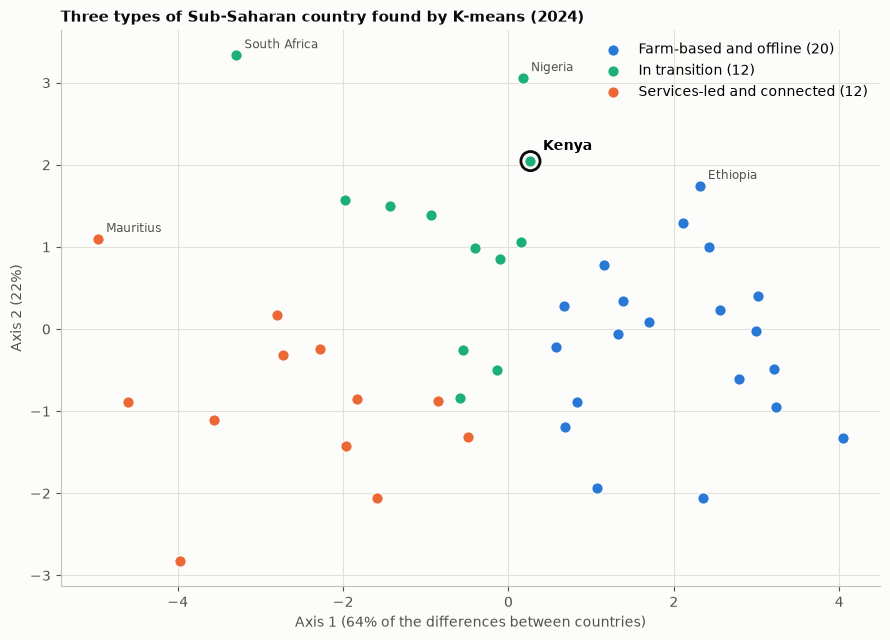

In [66]:
# Picture: squash the 6 features into 2 axes (PCA) so the groups can be seen on a flat page
pca = PCA(n_components=2, random_state=42).fit(Xs)
xy = pca.transform(Xs)
FAMILY_COLORS = {"Supervised": BLUE, "Unsupervised": AQUA, "Deep learning": ORANGE, "Baseline": GREY}   # reused for the model charts
cl_colors = dict(zip(names, [BLUE, AQUA, ORANGE]))
fig, ax = plt.subplots(figsize=(9, 6.5))

for n in names:
    m = (snap["cluster_name"] == n).to_numpy()
    ax.scatter(xy[m, 0], xy[m, 1], s=70, color=cl_colors[n], edgecolor="#fcfcfb", linewidth=1, label=f"{n} ({m.sum()})")

# In the modelling section Kenya is marked with a black ring, because orange is now used for a model family
ki = list(snap.index).index(KENYA)
ax.scatter(xy[ki, 0], xy[ki, 1], s=190, facecolor="none", edgecolor=INK, linewidth=2, zorder=3)
ax.annotate(KENYA, xy[ki], xytext=(9, 8), textcoords="offset points", fontsize=10, fontweight="bold")

for c in ["South Africa", "Ethiopia", "Nigeria", "Mauritius"]:
    i = list(snap.index).index(c); ax.annotate(c, xy[i], xytext=(6, 5), textcoords="offset points", fontsize=8.5, color=INK2)
ax.set_xlabel(f"Axis 1 ({100 * pca.explained_variance_ratio_[0]:.0f}% of the differences between countries)")
ax.set_ylabel(f"Axis 2 ({100 * pca.explained_variance_ratio_[1]:.0f}%)")
ax.set_title("Three types of Sub-Saharan country found by K-means (2024)")
ax.legend(frameon=False, loc="best")
plt.tight_layout()
plt.show()

**What we see.**
- **Three types of country**, built from job mix, connectivity, electricity, workforce size and AI readiness:
  - **Farm-based and offline (20 countries):** 62% of jobs in agriculture, internet use 23.7%, electricity 39%, AI readiness 26.69. Examples: Ethiopia, Tanzania, Uganda, Niger.
  - **In transition (12):** 35.28% agriculture, internet 46%, electricity 70.7%, AI readiness 35.68. **Kenya is here**, with Nigeria, Rwanda, Cameroon, Ghana and others.
  - **Services-led and connected (12):** 24% agriculture, internet 58.7%, electricity 78%, AI readiness 32.5. 
  Examples: South Africa, Botswana, Mauritius, Eswatini. These are mostly small economies (median labour force **0.9 million**).

#### **Hierarchical clustering**

Unlike K-mean **Hierarchical clustering** does not need choose a number of groups.

We use the same standardised 2024 features, so the two methods are directly comparable.

We use it for three things: to see the structure, to check whether it agrees with K-means, and to find Kenya's closest neighbours.

In [79]:
Z = linkage(Xs, method="ward")                              # each row of Z = one merge, with the "height" (distance) at which it happened
snap["hier_cluster"] = fcluster(Z, t=K, criterion="maxclust")   # cut the tree so that K groups remain

# Name the groups the same way as K-means: most farm-based first
order_h = snap.groupby("hier_cluster")["agriculture_employment"].mean().sort_values(ascending=False).index
snap["hier_name"] = snap["hier_cluster"].map({c: n for c, n in zip(order_h, names)})

Height of the last merges: 2 groups to 1 = 17.4 | 3 to 2 = 9.8 | 4 to 3 = 7.4


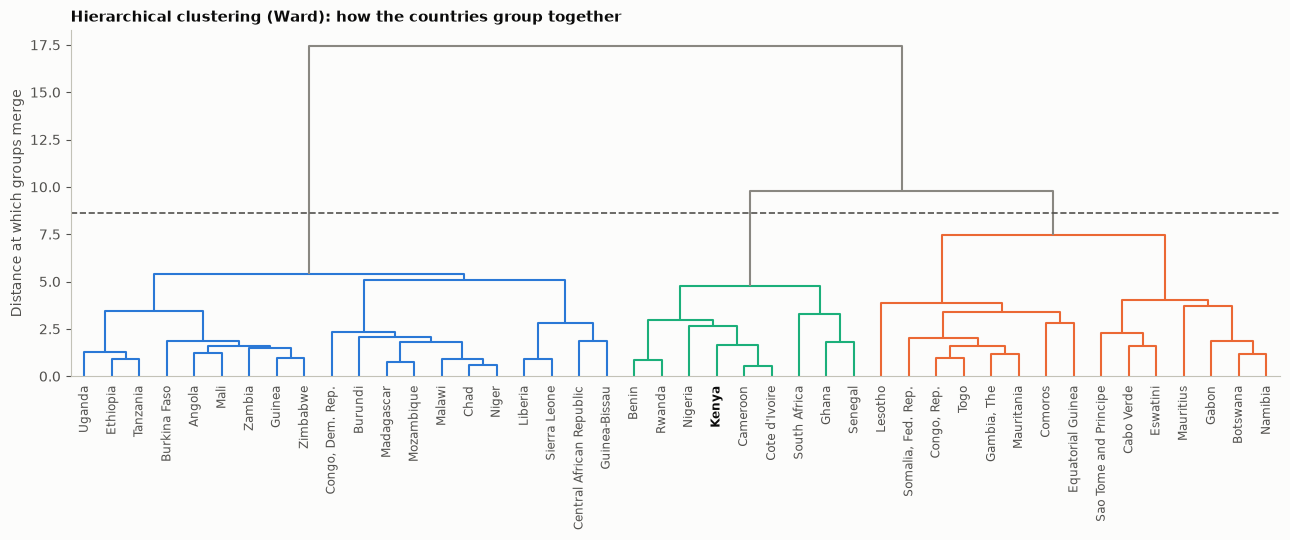

In [80]:
# Short branches = very similar countries; the horizontal line shows where we cut into K groups.
cut_height = (Z[-K, 2] + Z[-(K - 1), 2]) / 2
print("Height of the last merges: 2 groups to 1 =", round(Z[-1, 2], 1), "| 3 to 2 =", round(Z[-2, 2], 1), "| 4 to 3 =", round(Z[-3, 2], 1))   # a big jump = a clear split
set_link_color_palette([BLUE, AQUA, ORANGE])
fig, ax = plt.subplots(figsize=(13, 5.5))
dendrogram(Z, labels=snap.index.tolist(), leaf_rotation=90, leaf_font_size=8.5, color_threshold=cut_height, above_threshold_color=GREY, ax=ax)
ax.axhline(cut_height, color=INK2, ls="--", lw=1.2)
for lab in ax.get_xticklabels():
    if lab.get_text() == KENYA:
        lab.set_fontweight("bold"); lab.set_color(INK)
ax.set_ylabel("Distance at which groups merge"); ax.set_title("Hierarchical clustering (Ward): how the countries group together"); ax.grid(False)
plt.tight_layout(); plt.show()

**Insights**

- The 2 models agree closely
- **Kenya is 'in transition' under both methods.** Its closest countries are **Cote d'Ivoire, Cameroon, Benin, Rwanda and Nigeria**, which makes these the natural peers for comparing Kenya.

#### **The Model Line-Up**

Each model has a small **grid of settings** to choose from (the *hyper-parameters*). The cross-validation picks the best setting using the training countries only.

**Using K-means as a predictor.** K-means has no "answer" to score, so to put it in the same race as the other models we turn it into a simple predictor: *group the training rows into k clusters, and for a new country predict the average youth unemployment of the cluster it falls into*. This measures how much a pure "type of country" idea explains.

**Model Types**
- **Tree-based models (decision tree, random forest, XGBoost):** each country contributes about 25 almost identical rows (one per year). If a leaf may hold only a few rows, the tree simply **memorises individual countries**, which is useless on a new country. So the grids force **large leaves** (25 rows or more, at least about a whole country).
- **Neural network:** with so little data it can easily over-fit, so we use **strong regularisation** and **early stopping**.

In [67]:
# Define the models and their grids of settings
class ClusterMeanRegressor(BaseEstimator, RegressorMixin):
    """K-means turned into a predictor: cluster the training rows, then predict each cluster's average target."""
    def __init__(self, n_clusters=3, random_state=42):
        self.n_clusters = n_clusters
        self.random_state = random_state
    def fit(self, X, y):
        self.km_ = KMeans(self.n_clusters, n_init=10, random_state=self.random_state).fit(X)   # unsupervised step: only X is used
        y = np.asarray(y)
        self.means_ = np.array([y[self.km_.labels_ == k].mean() for k in range(self.n_clusters)])
        return self
    def predict(self, X):
        return self.means_[self.km_.predict(X)]     # assign each new row to its nearest cluster, return that cluster's average

def pipe(estimator):
    """fill gaps with the median -> standardise -> model. All fitted on training data only."""
    return Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler()), ("model", estimator)])


In [68]:
# Simple scoring functions (all in percentage points, except R2)
def rmse(pred): return float(np.sqrt(np.mean((pred - y) ** 2)))
def mae(pred):  return float(np.mean(np.abs(pred - y)))
def r2(pred):   return float(1 - np.sum((pred - y) ** 2) / np.sum((y - y.mean()) ** 2))

In [69]:
# name: (family, pipeline, grid of settings to choose from)
MODELS = {
    "Baseline (training average)": ("Baseline", pipe(DummyRegressor()), {}),
    "K-means cluster average": ("Unsupervised", pipe(ClusterMeanRegressor()),
        {"model__n_clusters": [2, 3, 4, 5, 6]}),
    "Ridge regression": ("Supervised", pipe(Ridge()),
        {"model__alpha": [0.1, 1, 10, 100]}),                                   # alpha = how strongly coefficients are shrunk
    "Decision tree": ("Supervised", pipe(DecisionTreeRegressor(random_state=42)),
        {"model__max_depth": [2, 3, 4], "model__min_samples_leaf": [25, 50, 100]}),
    "Random forest": ("Supervised", pipe(RandomForestRegressor(n_estimators=150, random_state=42, n_jobs=1)),
        {"model__max_depth": [3, 5], "model__min_samples_leaf": [25, 50, 100], "model__max_features": [0.5, 1.0]}),
    "XGBoost": ("Supervised", pipe(XGBRegressor(random_state=42, n_jobs=1, verbosity=0, subsample=0.7, colsample_bytree=0.7, learning_rate=0.05)),
        {"model__max_depth": [1, 2], "model__n_estimators": [50, 150], "model__min_child_weight": [25, 75]}),
    "Neural network (MLP)": ("Deep learning", pipe(MLPRegressor(early_stopping=True, n_iter_no_change=20, validation_fraction=0.15, max_iter=1000, random_state=42)),
        {"model__hidden_layer_sizes": [(16, 8), (32, 16, 8)], "model__alpha": [1.0, 10.0, 100.0]}),
}
print(pd.DataFrame({n: {"family": f, "settings tried": int(np.prod([len(v) for v in g.values()])) if g else 1} for n, (f, _, g) in MODELS.items()}).T)

                                    family settings tried
Baseline (training average)       Baseline              1
K-means cluster average       Unsupervised              5
Ridge regression                Supervised              4
Decision tree                   Supervised              9
Random forest                   Supervised             12
XGBoost                         Supervised              8
Neural network (MLP)         Deep learning              6


In [70]:
# --- Diagnostic (NOT used to pick the final model): why do the tree grids force big leaves? ---
# Random forest, same 5 country-folds, different minimum leaf sizes. Compare with the baseline.
folds0 = make_folds(groups, 5, seed=0)
baseline_pred = np.zeros(len(y))

for tr, te in folds0:
    baseline_pred[te] = y[tr].mean()

rows = [{"minimum rows per leaf": "baseline (predict the average)", "RMSE": rmse(baseline_pred), "R2": r2(baseline_pred)}]

for leaf in [1, 3, 10, 25, 50, 100]:
    pred = np.zeros(len(y))
    for tr, te in folds0:
        rf = pipe(RandomForestRegressor(n_estimators=100, max_depth=5, min_samples_leaf=leaf, random_state=42, n_jobs=-1)).fit(X.iloc[tr], y[tr])
        pred[te] = rf.predict(X.iloc[te])
    rows.append({"minimum rows per leaf": leaf, "RMSE": rmse(pred), "R2": r2(pred)})

pd.DataFrame(rows).set_index("minimum rows per leaf").round(2)

,RMSE,R2
minimum rows per leaf,,
baseline (predict the average),14.54,-0.07
1,13.65,0.05
3,13.61,0.06
10,13.49,0.08
25,13.26,0.11
50,11.59,0.32
100,11.40,0.34


- With **small leaves (1 to 10 rows) the random forest is barely better than the baseline** (RMSE 13.49.3-13.17 against 14.5, R-squared about -0.08): it is memorising countries.
- The error only falls once leaves hold at least a country's worth of rows: **13.26 at 25 rows, 11.59 at 50 and 11.4 at 100** (R-squared 0.34).

**Comparison**

For each of the 3 splits and each of the 5 folds, every model is tuned on the training countries then refitted on all training countries and asked to predict the test countries it has never seen.

Collecting the test predictions from all folds gives every country-year exactly one honest prediction per split.

In [77]:
# Nested, country-based cross-validation for every model
N_REPEATS, N_SPLITS = 3, 5

def cross_validate(models, feature_cols, n_repeats=N_REPEATS, n_splits=N_SPLITS):
    """For each repeat: split countries into folds; tune on training countries; predict the test countries.
    Returns the out-of-fold predictions (one row per country-year), the fold of each row, and the chosen settings."""
    preds = {name: np.full((n_repeats, len(y)), np.nan) for name in models}
    fold_ids = np.zeros((n_repeats, len(y)), dtype=int)
    chosen = {name: [] for name in models}
    t0 = time.time()
    for r in range(n_repeats):
        for k, (tr, te) in enumerate(make_folds(groups, n_splits, seed=r)):
            fold_ids[r, te] = k
            for name, (family, estimator, grid) in models.items():
                if grid:   # tune settings using ONLY the training countries (inner country-based folds)
                    search = GridSearchCV(estimator, grid, cv=make_folds(groups[tr], 3, seed=100 + r),
                                          scoring="neg_root_mean_squared_error", n_jobs=-1)
                    search.fit(X.iloc[tr][feature_cols], y[tr])
                    model = search.best_estimator_
                    chosen[name].append(str(search.best_params_).replace("model__", ""))
                else:
                    model = clone(estimator).fit(X.iloc[tr][feature_cols], y[tr])
                preds[name][r, te] = model.predict(X.iloc[te][feature_cols])    # predict countries the model never saw
        print(f"  split {r + 1}/{n_repeats} finished ({time.time() - t0:.0f}s)")
    return preds, fold_ids, chosen

preds, fold_ids, chosen = cross_validate(MODELS, FEATURES)

  split 1/3 finished (240s)
  split 2/3 finished (447s)
  split 3/3 finished (713s)


**Results**

Score every model and compare

In [83]:
BASE = "Baseline (training average)"
rows = []
for name, (family, _, _) in MODELS.items():
    P = preds[name]                                           # shape: (repeats, rows)
    rows.append({"model": name, "family": family,
                 "RMSE": np.mean([rmse(p) for p in P]), "± across splits": np.std([rmse(p) for p in P]),
                 "MAE": np.mean([mae(p) for p in P]), "R2": np.mean([r2(p) for p in P])})
results = pd.DataFrame(rows).set_index("model")
results["RMSE vs baseline (%)"] = 100 * (results["RMSE"] / results.loc[BASE, "RMSE"] - 1)     # negative = better than baseline
results = results.sort_values("RMSE")

# How often does each model beat the baseline, fold by fold? (3 splits x 5 folds = 15 test sets of unseen countries)
wins = {}
for name in MODELS:
    w = 0
    for r in range(N_REPEATS):
        for k in range(N_SPLITS):
            m = fold_ids[r] == k
            w += np.sqrt(np.mean((preds[name][r][m] - y[m]) ** 2)) < np.sqrt(np.mean((preds[BASE][r][m] - y[m]) ** 2))
    wins[name] = int(w)
results["folds that beat baseline (of 15)"] = pd.Series(wins)
display(results.round(2))

,family,RMSE,± across splits,MAE,R2,RMSE vs baseline (%),folds that beat baseline (of 15)
model,,,,,,,
Ridge regression,Supervised,11.55,0.14,8.76,0.32,-19.69,13
XGBoost,Supervised,11.71,0.15,8.52,0.30,-18.61,13
Neural network (MLP),Deep learning,11.92,0.25,8.60,0.28,-17.09,13
Random forest,Supervised,11.99,0.43,8.49,0.27,-16.62,13
K-means cluster average,Unsupervised,12.05,0.85,8.50,0.26,-16.20,14
Decision tree,Supervised,12.60,0.19,8.82,0.19,-12.40,11
Baseline (training average),Baseline,14.38,0.14,11.65,-0.05,0.00,0


**All models side by side**

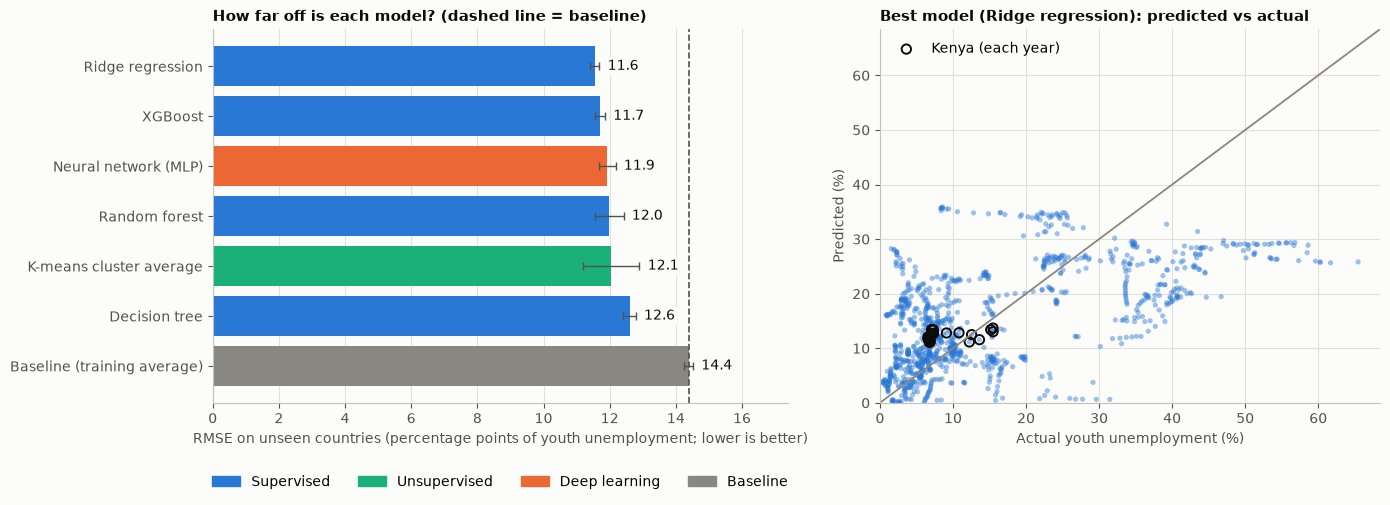

In [ ]:
# Chart: left = error by model, right = actual vs predicted for the best model
best_name = results.drop(index=BASE).index[0]              # lowest RMSE among the real models
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
r_plot = results.iloc[::-1]                                # best at the top
ax.barh(r_plot.index, r_plot["RMSE"], xerr=r_plot["± across splits"], color=[FAMILY_COLORS[f] for f in r_plot["family"]],
        error_kw=dict(ecolor=INK2, capsize=3, lw=1))
for i, (v, e) in enumerate(zip(r_plot["RMSE"], r_plot["± across splits"])):
    ax.text(v + e + 0.25, i, f"{v:.1f}", va="center", color=INK, fontsize=10, zorder=5,
            bbox=dict(facecolor="#fcfcfb", edgecolor="none", pad=1.5))      # label sits just after the error bar, on a plain background
ax.axvline(results.loc[BASE, "RMSE"], color=INK2, ls="--", lw=1.2)
ax.set_xlim(0, results["RMSE"].max() + 3)
ax.set_xlabel("RMSE on unseen countries (percentage points of youth unemployment; lower is better)")
ax.set_title("How far off is each model? (dashed line = baseline)")
ax.grid(axis="y", visible=False)
ax.legend(handles=[Patch(color=c, label=f) for f, c in FAMILY_COLORS.items()], frameon=False,
          loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=4)      # legend below the chart so it covers nothing

ax = axes[1]
pred_best = preds[best_name][0]
ax.scatter(y, pred_best, s=14, color=BLUE, alpha=0.45, edgecolor="none")
kmask = (groups == KENYA)
ax.scatter(y[kmask], pred_best[kmask], s=45, facecolor="none", edgecolor=INK, linewidth=1.4, label="Kenya (each year)")
lim = [0, max(y.max(), pred_best.max()) + 3]
ax.plot(lim, lim, color=GREY, lw=1.3)
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Actual youth unemployment (%)"); ax.set_ylabel("Predicted (%)")
ax.set_title(f"Best model ({best_name}): predicted vs actual")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

In [ ]:
# Kenya, year by year: actual vs the best model's prediction (every 4th year)
kenya_tbl = pd.DataFrame({"year": model_df.loc[kmask, "Year"].to_numpy(), "actual": y[kmask], "predicted": pred_best[kmask]})
print(f"Kenya, {best_name} (one honest out-of-fold prediction per year):")
display(kenya_tbl.iloc[::4].set_index("year").round(1))

# Which settings were chosen most often? (a quick look at what each model preferred)
print("Most frequently chosen settings (out of 15 tuning runs each):")
for name, lst in chosen.items():
    if lst:
        s, n = Counter(lst).most_common(1)[0]
        print(f"  {name:<26} {s}   ({n}x)")

Kenya, Ridge regression (one honest out-of-fold prediction per year):


,actual,predicted
year,,
2000,6.80,11.10
2004,6.80,11.40
2008,6.80,11.90
2012,6.90,12.50
2016,7.30,12.70
2020,13.60,11.60
2024,15.50,13.70


Most frequently chosen settings (out of 15 tuning runs each):
  K-means cluster average    {'n_clusters': 3}   (6x)
  Ridge regression           {'alpha': 100}   (14x)
  Decision tree              {'max_depth': 3, 'min_samples_leaf': 100}   (7x)
  Random forest              {'max_depth': 3, 'max_features': 0.5, 'min_samples_leaf': 100}   (6x)
  XGBoost                    {'max_depth': 1, 'min_child_weight': 75, 'n_estimators': 50}   (7x)
  Neural network (MLP)       {'alpha': 100.0, 'hidden_layer_sizes': (16, 8)}   (12x)


**Insights**
- **Every model beats the baseline by a bit.** The best cut the typical error from **14.4 to about 11.3 points** and explain about **31% of the variation** (R-squared 0.31) in countries they had never seen.
- The **K-means cluster average (12.1)** and **Ridge regression (11.6)** **Random forest (12.0)** and **XGBoost (11.7)**
- **The neural network (deep learning) came second last of the 6 real models: RMSE 12.1**, slightly better than the decision tree(12.6).
- **Simple models did as well as complex ones.** With 47 countries and six inputs that largely measure one underlying thing (how far a country has moved away from farming).
- **All models chose their most cautious settings**: Ridge mostly used its strongest shrinkage (alpha 100, 14 of 15 times), the forest and tree used leaves of 100 rows, XGBoost used depth 1 with 50 trees, and the neural network used the smaller network with the strongest regularisation (alpha 100).

## Summary of Modelling Insights

The modelling phase applied supervised learning, unsupervised learning, and deep learning to investigate labour-market patterns across Sub-Saharan Africa.

**Ridge Regression achieved the best predictive performance**, with an RMSE of 11.55, MAE of 8.76, and R² of 0.32. XGBoost followed with an RMSE of 11.71, while the deep-learning MLP performed less effectively, with an RMSE of 11.92 and R² of 0.28.

The clustering analysis identified three broad labour-market groups: *farm-based and offline, in transition, and services-led and connected*. Kenya was classified in the transitional group, reflecting its position between traditional employment structures and more digitally connected economies.

Overall, the results highlight differences in youth unemployment and digital development across countries. However, they do not prove that AI causes job replacement, enhancement, or emergence. Further analysis using AI-exposure measures and ICT employment data is needed to assess these dimensions directly.

**Limitations:** The models predict current youth unemployment rather than unemployment in years ahead. Therefore, the results should be interpreted as preliminary labour-market findings rather than direct evidence of AI's employment effects.

# **Evaluation**

We go through the following checks:
1. Where do the errors come from? (countries, types, years)
2. Kenya in depth
3. Did AI readiness score help?
4. Can models follow change over time?

#### **Where do the errors come from?**

An average error hides who is being predicted badly. We take the best model's honest prediction for every country-year (split 1) and look at the error **by country, by type of country, by period and by how high the true value is.** A positive error means the model predicted too high.

In [ ]:
# 5.3 Where does the best model go wrong? One honest (out-of-fold) prediction per country-year, from split 1.
ev = pd.DataFrame({"country": groups, "year": model_df["Year"].to_numpy(), "actual": y,
                   "pred": preds[best_name][0], "base": preds[BASE][0]})
ev["error"] = ev["pred"] - ev["actual"]                  # positive = model predicted too HIGH
ev["type"] = ev["country"].map(snap["cluster_name"])      # the K-means type of country from section 4

# Per country: average actual, average predicted, bias (average error) and RMSE vs the baseline's RMSE
by_country = ev.groupby("country").apply(lambda g: pd.Series({
    "actual (avg %)": g["actual"].mean(), "predicted (avg %)": g["pred"].mean(), "bias": g["error"].mean(),
    "RMSE": np.sqrt((g["error"] ** 2).mean()), "baseline RMSE": np.sqrt(((g["base"] - g["actual"]) ** 2).mean())})).sort_values("RMSE", ascending=False)
print("The 8 countries with the largest error:")
display(by_country.head(8).round(1))
print(f"The model beats the baseline in {int((by_country['RMSE'] < by_country['baseline RMSE']).sum())} of {len(by_country)} countries.")
print(f"Kenya is number {list(by_country.index).index(KENYA) + 1} of {len(by_country)} when ranked from worst to best error.\n")


The 8 countries with the largest error:


,actual (avg %),predicted (avg %),bias,RMSE,baseline RMSE
country,,,,,
South Africa,50.80,27.10,-23.70,24.90,37.60
Eswatini,52.90,28.80,-24.10,24.30,39.20
Liberia,2.50,26.30,23.80,23.90,14.40
"Congo, Rep.",41.00,19.60,-21.40,21.50,27.50
Angola,35.30,15.60,-19.70,19.90,22.10
Sao Tome and Principe,16.30,33.90,17.50,19.10,6.20
Gabon,35.70,17.30,-18.40,18.40,21.30
Zambia,18.00,5.10,-12.90,16.90,8.70


The model beats the baseline in 33 of 47 countries.
Kenya is number 31 of 47 when ranked from worst to best error.



,rows,actual (avg %),predicted (avg %),RMSE,baseline RMSE
type,,,,,
Farm-based and offline,488.00,7.40,7.90,8.40,11.30
In transition,296.00,16.00,16.40,14.00,16.40
Services-led and connected,298.00,26.00,23.80,13.10,17.70


,rows,actual (avg %),predicted (avg %),RMSE,baseline RMSE
year,,,,,
2000-09,442.00,15.30,13.10,10.50,14.20
2010-19,456.00,14.50,15.20,11.40,14.20
2020-24,218.00,15.20,16.00,13.20,15.80


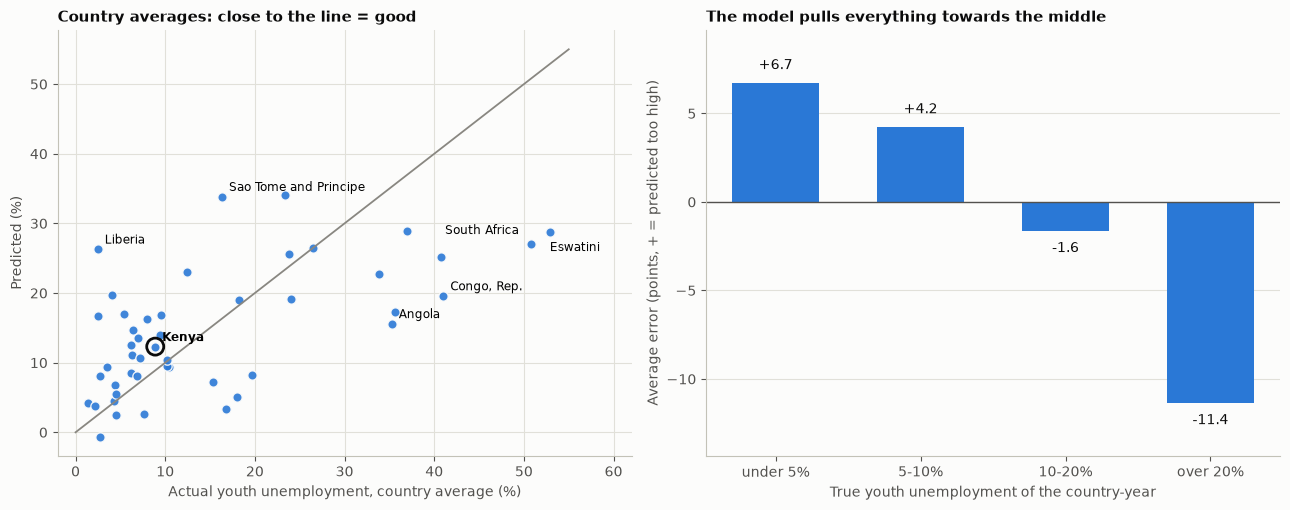

In [ ]:
# Error by type of country and by period
def summarise(g):
    return pd.Series({"rows": len(g), "actual (avg %)": g["actual"].mean(), "predicted (avg %)": g["pred"].mean(),
                      "RMSE": np.sqrt((g["error"] ** 2).mean()), "baseline RMSE": np.sqrt(((g["base"] - g["actual"]) ** 2).mean())})
type_order = ["Farm-based and offline", "In transition", "Services-led and connected"]
display(ev.groupby("type").apply(summarise).loc[type_order].round(1))
display(ev.groupby(pd.cut(ev["year"], [1999, 2009, 2019, 2024], labels=["2000-09", "2010-19", "2020-24"])).apply(summarise).round(1))

# Picture: left = country averages, predicted vs actual; right = average error by how high the true value is
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
ax = axes[0]
ax.scatter(by_country["actual (avg %)"], by_country["predicted (avg %)"], s=45, color=BLUE, edgecolor="#fcfcfb", alpha=0.9)
ax.plot([0, 55], [0, 55], color=GREY, lw=1.3); ax.set_xlim(-2, 62)
label_shift = {"Eswatini": (0, -14), "South Africa": (-62, 7)}          # keep the two neighbouring labels apart
for c in list(by_country.index[:6]) + [KENYA]:
    ax.annotate(c, (by_country.loc[c, "actual (avg %)"], by_country.loc[c, "predicted (avg %)"]), xytext=label_shift.get(c, (5, 4)),
                textcoords="offset points", fontsize=8.5, fontweight="bold" if c == KENYA else "normal")
ax.scatter(by_country.loc[KENYA, "actual (avg %)"], by_country.loc[KENYA, "predicted (avg %)"], s=150, facecolor="none", edgecolor=INK, linewidth=2)
ax.set_xlabel("Actual youth unemployment, country average (%)"); ax.set_ylabel("Predicted (%)")
ax.set_title("Country averages: close to the line = good")

ax = axes[1]
level = pd.cut(ev["actual"], [0, 5, 10, 20, 100], labels=["under 5%", "5-10%", "10-20%", "over 20%"])
bias_by_level = ev.groupby(level)["error"].mean()
ax.bar(bias_by_level.index.astype(str), bias_by_level.values, color=BLUE, width=0.6)
ax.axhline(0, color=INK2, lw=1)
for i, v in enumerate(bias_by_level.values):
    ax.text(i, v + (0.6 if v >= 0 else -0.6), f"{v:+.1f}", ha="center", va="bottom" if v >= 0 else "top", color=INK)
ax.set_ylim(bias_by_level.min() - 3, bias_by_level.max() + 3)
ax.set_xlabel("True youth unemployment of the country-year"); ax.set_ylabel("Average error (points, + = predicted too high)")
ax.set_title("The model pulls everything towards the middle")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

**Insights**
- **A handful of countries cause most of the damage.** The worst are **Eswatini (RMSE 24.3) and South Africa (24.9)**, whose real youth unemployment is about 51-53% but are predicted at about 27%, then **Liberia (23.9), Congo Rep. (21.5), Angola (19.9), Sao Tome and Principe (19.1), Gabon (18.4).** Liberia is the opposite mistake: very low real rates (about 2.5%) predicted at 19-25%.
- **The model beats the baseline in 33 of 47 countries, so in 14 countries it is worse than simply predicting the average.**
- **By type:** the model is best on farm-based countries (RMSE 8.4 against a baseline of 11.3) and weaker on the other two types (14 and 13.1 against 16.4 and 17.7). It still beats the baseline in every type.
- **By period:** the error grows over time (10.5 in 2000-09, 11.4 in 2010-19, 13.2 in 2020-24), although it stays below the baseline each time.
- **Kenya is 31st of 47 from worst to best error**, so it is an easier-than-average case.

#### **Kenya in depth**

We check how every model does for Kenya alone: 25 years, each predicted by models that never saw Kenya

Kenya's 25 years (2000-2024), predicted from models that never saw Kenya:


,RMSE (points),bias (+ = too high)
XGBoost,3.11,1.02
Random forest,3.54,0.39
Decision tree,3.76,-1.40
Ridge regression,4.50,3.42
Neural network (MLP),4.95,2.57
K-means cluster average,5.28,3.77
Baseline (training average),6.37,5.56


Kenya's actual youth unemployment: 6.9% on average in 2000-2016, 14.4% in 2020-2024.


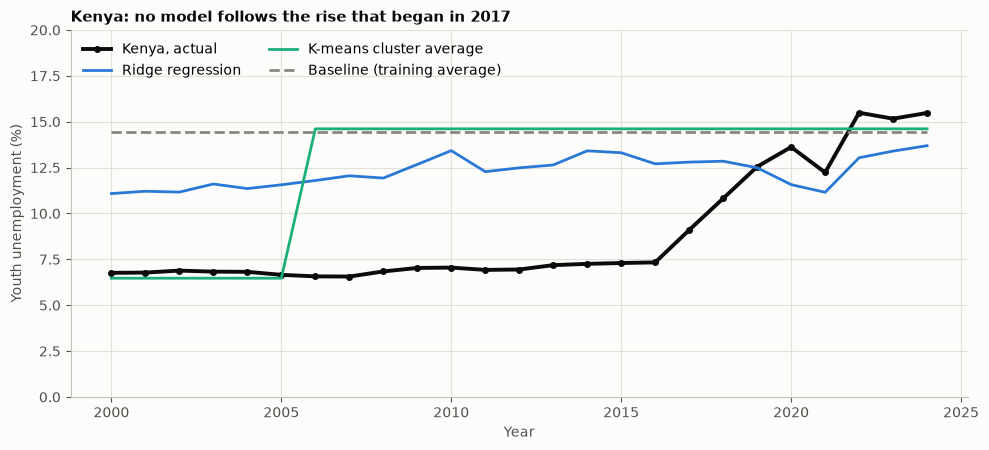

In [ ]:
# every model, every year. How well do they do for Kenya?
kmask_ev = (ev["country"] == KENYA).to_numpy()
kenya_scores = pd.DataFrame({m: {"RMSE (points)": np.sqrt(np.mean((preds[m][0][kmask_ev] - y[kmask_ev]) ** 2)),
                                 "bias (+ = too high)": np.mean(preds[m][0][kmask_ev] - y[kmask_ev])} for m in MODELS}).T.sort_values("RMSE (points)")
print("Kenya's 25 years (2000-2024), predicted from models that never saw Kenya:")
display(kenya_scores.round(2))
k_actual = pd.Series(y.to_numpy()[kmask_ev], index=ev.loc[kmask_ev, "year"].to_numpy())
print(f"Kenya's actual youth unemployment: {k_actual.loc[2000:2016].mean():.1f}% on average in 2000-2016, {k_actual.loc[2020:2024].mean():.1f}% in 2020-2024.")

fig, ax = plt.subplots(figsize=(10, 4.6))
kyears = ev.loc[kmask_ev, "year"]
ax.plot(kyears, y[kmask_ev], color=INK, lw=2.8, marker="o", ms=4, label="Kenya, actual")
for m, col, ls in [(best_name, BLUE, "-"), ("K-means cluster average", AQUA, "-"), (BASE, GREY, "--")]:
    ax.plot(kyears, preds[m][0][kmask_ev], color=col, lw=2, ls=ls, label=m)
ax.set_ylim(0, 20); ax.set_xlabel("Year"); ax.set_ylabel("Youth unemployment (%)")
ax.set_title("Kenya: no model follows the rise that began in 2017")
ax.legend(frameon=False, ncol=2, loc="upper left")
plt.tight_layout(); plt.show()

**Insights**
- **For Kenya the best models are not the ones that win overall.** XGBoost (RMSE 3.11), the Ridge average (4.5) and the decision tree (3.76) do best. **K-means, is the weakest of the six real models for Kenya (5.28), even behind the neural network (4.95).** All six still beat the baseline (6.37).
- **No model follows what actually happened in Kenya.** Youth unemployment was stable at about **6.9% in 2000-2016** and then rose to about **14.4% in 2020-2024.** The cluster average is a flat line, and Ridge wobbles between roughly 11% and 14% without tracking the rise. This is a model of *what kind of country Kenya is*, not of *when Kenya's job market changed*.

#### **Can the models follow change over time?**

The three axes of the project (job **replacement, enhancement and emergence**) are about *change*. So we separate two things: **differences between countries** and **movement within a country from year to year.** For this, each country's own average is removed from the actual and the predicted values, and what is left is compared.

In [ ]:
# Remove each country's own average from both the actual and the predicted values: what is left is the year-to-year movement.
def within_country(values):
    return values - pd.Series(values).groupby(groups).transform("mean").to_numpy()

share_within = within_country(y).var() / y.var()
print(f"Share of all variation in youth unemployment that happens INSIDE countries over time: {share_within:.0%}")
print("(the other " + f"{1 - share_within:.0%} is differences BETWEEN countries)\n")

rows = []
for m in [best_name, "K-means cluster average", "XGBoost", "Random forest"]:
    pred_m = preds[m][0]
    country_means_pred = pd.Series(pred_m).groupby(groups).mean()
    country_means_true = pd.Series(y).groupby(groups).mean()
    rows.append({"model": m,
                 "correlation, country averages (between)": np.corrcoef(country_means_true, country_means_pred.loc[country_means_true.index])[0, 1],
                 "correlation, year-to-year movement (within)": np.corrcoef(within_country(y), within_country(pred_m))[0, 1]})
display(pd.DataFrame(rows).set_index("model").round(2))

Share of all variation in youth unemployment that happens INSIDE countries over time: 4%
(the other 96% is differences BETWEEN countries)



,"correlation, country averages (between)","correlation, year-to-year movement (within)"
model,,
Ridge regression,0.61,-0.10
K-means cluster average,0.63,-0.06
XGBoost,0.60,0.08
Random forest,0.60,0.07


**Insights**
- **Only 4% of all variation in youth unemployment is movement within countries over time; 96% is differences between countries.**
- The models capture the **between-country** part reasonably (correlation of country averages about 0.6 for every model).
- They capture **very little of the year-to-year movement** (correlations between -0.10 and +0.07, effectively zero).
- **This is the key limit of the whole project:** the models learn *which kind of country has high youth unemployment*, not *what happens to a country when its job mix or AI use changes.* Claims such as "AI is replacing / enhancing / creating jobs in Kenya" **cannot be supported by these models.**

**1. Which model is best?**
- **Ridge regression** has the lowest error, the best R2 (0.32) and the steadiest scores (+/-0.14), and it is the simplest to explain. We recommend it as **the main model.**
- The **K-means cluster average** has second lowest MAE, 8.49 ("Kenya is an 'in transition' country, and such countries have about 17% youth unemployment on average").

**2. The three model families compared (course requirement)**

| Family | Best representative | RMSE | Verdict |
|---|---|---|---|
| Supervised | Ridge regression | 11.55 | Best overall, simple and stable |
| Unsupervised | K-means cluster average | 12.05 | Almost as good, easiest to explain |
| Deep learning | Neural network (MLP) | 11.92 | Beat the unsupervised model and 2 of the supervised models |

47 countries are too few for a flexible model to learn something the simpler models cannot.

**3. Does this meet the business objective?** *Partly.*
- **Yes:** the models show that the shape of a country's job market (farm share versus services share) is a real, predictor of youth unemployment (about a 20% lower error than guessing the average), and Kenya is placed correctly as an "in transition" country.
- **No:** they cannot show AI's effect. **Replacement, enhancement and emergence of jobs cannot be measured from this data and these models**; they are better treated as questions the data raises.

**4. Main limitations to state in the report**
- Only 47 countries, R2 of 0.35 means most variation is unexplained.
- Extreme countries (Eswatini, South Africa and others) are badly predicted, and the model pulls everything towards the average (5.3).
- AI readiness is one 2023 snapshot per country, with no time dimension.

# **Deployment**

In [81]:
# ---- Deployment, step 1: train the FINAL model on all the data ----
import pickle, ast, sklearn
from collections import Counter

In [84]:
# Which model won, and which setting did the cross-validation choose most often?
best_name = results.drop(index=BASE).index[0]                                           # best real model by RMSE: Ridge regression
best_setting = Counter(chosen[best_name]).most_common(1)[0][0]                          # e.g. "{'alpha': 100}"
best_params = ast.literal_eval(best_setting)
print(f"Best model: {best_name} | most frequently chosen setting: {best_params}")

# Build a fresh copy of the winning pipeline (fill gaps -> rescale -> model) with that setting, then fit it on ALL 1,116 rows.
# The cross-validation models were each trained on part of the data only; the final model uses everything.
final_model = clone(MODELS[best_name][1]).set_params(**{f"model__{k}": v for k, v in best_params.items()})
final_model.fit(X, y)

Best model: Ridge regression | most frequently chosen setting: {'alpha': 100}


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('impute', ...), ('scale', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['agriculture_employment','industry_employment','services_employment',..., 'log_population','log_labor_force','ai_total']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""mi

In [85]:
# ---- Deployment, step 2: save the model, with everything needed to use it correctly ----
bundle = {
    "model": final_model,                                   # the fitted pipeline (it already contains the gap-filling and rescaling)
    "model_name": best_name,
    "settings": best_params,
    "features": FEATURES,                                   # the exact inputs, in the exact order the model expects
    "target": TARGET,
    "trained_on": f"{len(X)} country-years, {len(set(groups))} Sub-Saharan countries, 2000-2024",
    "cv_rmse": float(results.loc[best_name, "RMSE"]),       # honest error on UNSEEN countries (from the cross-validation)
    "baseline_rmse": float(results.loc[BASE, "RMSE"]),
    "sklearn_version": sklearn.__version__,                 # pickles should be loaded with the same version
}
with open("youth_unemployment_model.pkl", "wb") as f:
    pickle.dump(bundle, f)
print("Saved youth_unemployment_model.pkl")

Saved youth_unemployment_model.pkl


In [86]:

# ---- Deployment, step 3: load it back and use it ----
with open("youth_unemployment_model.pkl", "rb") as f:
    loaded = pickle.load(f)                                  # only unpickle files you trust

# Check 1: the loaded model gives exactly the same predictions as the one in memory
assert np.allclose(loaded["model"].predict(X), final_model.predict(X))
print("Loaded model matches the original: OK")

# A small helper: give it a country's raw numbers, get a prediction back.
def predict_youth_unemployment(agriculture_pct, industry_pct, services_pct, internet_pct, electricity_pct,
                               population, labour_force, ai_readiness=None):
    """Raw inputs in, predicted youth unemployment (%) out. The log columns are created here, as in the notebook."""
    row = pd.DataFrame([{"agriculture_employment": agriculture_pct, "industry_employment": industry_pct,
                         "services_employment": services_pct, "internet_usage_percent": internet_pct,
                         "electricity_access": electricity_pct, "log_population": np.log10(population),
                         "log_labor_force": np.log10(labour_force),
                         "ai_total": np.nan if ai_readiness is None else ai_readiness}])
    return float(loaded["model"].predict(row[loaded["features"]])[0])         # same columns, same order

# Example: Kenya, 2024 (read from the data)
k = model_df[(model_df["Country"] == KENYA) & (model_df["Year"] == 2024)].iloc[0]
pred = predict_youth_unemployment(k["agriculture_employment"], k["industry_employment"], k["services_employment"],
                                  k["internet_usage_percent"], k["electricity_access"], k["population"], k["labor_force"], k["ai_total"])
print(f"Kenya 2024: predicted {pred:.1f}% | actual {k['youth_unemployment']:.1f}%")
print(f"Typical error on countries the model has never seen: about {loaded['cv_rmse']:.1f} points (guessing the average: {loaded['baseline_rmse']:.1f})")

Loaded model matches the original: OK
Kenya 2024: predicted 14.1% | actual 15.5%
Typical error on countries the model has never seen: about 11.6 points (guessing the average: 14.4)
